# CM laser calibration v5: alignment → space charge → static, final parametrization (2026-10-23)
**Everything in this notebook uses the final calibration** and is compared with the current CDB:
- **Space charge**: keff = a I − 0.015 I², a = 0.70 (South) / 0.68 (North), I = per-side median GEM current (CDB GEM payload
  "SOUTH" / "NORTH"); maps South α 1.7 kink 25 cm, North α 1.6 kink 25 cm.
- **Static** (vs the automatic voltages, m = 120 module-frame maps): 795xx South IFC −4 V / OFC +4 V / frames −157, North IFC −43 V
  / OFC −6 V / frames −182; 80892 and 81558 with their own static (Section 3).
- Explicit jobs (v9): `f9_static` = final static, no space charge (differences between runs = the measured space-charge
  change), `f9_s795` = final calibration with the 795xx static on every run, `f9_sper` = with each period's own static,
  `f9_lin` = linear keff 0.60 / 0.55 I on the same static (**comparison only**).

## The results in plain words
1. **The space-charge correction does not grow linearly with the GEM current**: from one block to the next the data change
   ≈ 20 % less per µA at 6 µA than at 2 µA. keff = a I − 0.015 I² describes all 17 beam blocks on both sides.
2. **With it the static needs only small field-cage voltages** (the old North IFC −112 … −138 V was compensating a too-small keff).
3. **The static is different in each run period** (795xx, 80892, 81558) – not with the current – so each period needs its own.
4. **Per pad module** the space-charge scale differs by up to ±30–40 % in a few modules (GEM gain × IBF); ≈ 15 % gain if used.
5. **P/T** is negligible (≤ 0.02 mrad).
6. **vs the CDB at 795xx**: dφ rms 0.45 / 0.26 mrad (CDB 0.58 / 0.83), sideways shift 0.08 / 0.05 mm (0.50 / 1.45), R² +56 /
   +13 µm (−31 / +50; K0s balance = +4 + 1.11 R²). At 8xxxx: 0.36–0.46 mrad (CDB 0.73–1.72), shift ≤ 0.3 mm (0.4–3.1).

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '/home/yoren/bnl/ROOT/install/lib')
import numpy as np, matplotlib.pyplot as plt
import cmplots as c, truthalign as ta, alignqa as aq, scdiff as sd, calib as cb, v5ana as v
import scqa as q, static7 as st, sc3d as d3, cal8 as k8, v9ana as v9, calfinal as cf
plt.rcParams['figure.dpi'] = 72
plt.rcParams.update({'font.size': 13, 'axes.titlesize': 13, 'axes.labelsize': 13, 'legend.fontsize': 9.5})
def show(*figs):
    for f in figs:
        display(f)
    plt.close('all')
ta.correct_truth()
d3.SPLIT_SOUTH = True
def qline(Q):
    return f"dphi rms {Q['rms']:.2f} mrad, shift {Q['shift']:+.2f} mm, R2 {Q['R2']:+5.0f} um, pointing {Q['pointing']:+.2f} mm, steps {Q['step1']:+.2f} / {Q['step2']:+.2f} mm, R1 arch {Q['arch']:+.2f} mrad"
for r in q.RUNS:
    print(r, 'blocks', [k for rr, k, a, b in sd.blocks((r,))], ' I_S %.2f  I_N %.2f uA' % (q.run_I(r, 0), q.run_I(r, 1)),
          '  final keff S %.3f  N %.3f' % (cf.k_final(0, q.run_I(r, 0)), cf.k_final(1, q.run_I(r, 1))))

79508 blocks [0, 1000]  I_S 2.70  I_N 2.83 uA   final keff S 1.778  N 1.803
79513 blocks [0, 1000, 2000]  I_S 2.12  I_N 2.24 uA   final keff S 1.417  N 1.446
79516 blocks [0, 1000, 2000]  I_S 1.84  I_N 1.94 uA   final keff S 1.236  N 1.263
79529 blocks [0, 1000, 2000]  I_S 2.10  I_N 2.20 uA   final keff S 1.403  N 1.422
80892 blocks [0, 1000, 2000]  I_S 5.63  I_N 6.01 uA   final keff S 3.466  N 3.544
81558 blocks [0, 1000, 2000]  I_S 6.34  I_N 6.62 uA   final keff S 3.834  N 3.845


**Where the data come from.** Laser images of the CM stripes in every run (raw clusters from the pad DSTs, re-clustered
and matched to the CM stripe pattern in our condor jobs, local ideal TPC coordinates, no tracking alignment – the CDB
TPC alignment is all zero anyway). Each configuration (static model × space-charge map × keff) corrects the same raw
clusters with PHGarfield; the corrected clusters are compared with the CM truth (stripe positions), which is aligned to
the pad plane with field off (Section 1). Runs: field off 78242, no beam 75073 / 83319, beam 795xx (11 blocks, I 1.8–2.7 µA)
and 80892 / 81558 (6 blocks, I 5.4–7.0 µA).

**Rules used from here on (v3).**
- **Comparisons**: dφ [mrad] vs the aligned truth, **nothing removed** (a rotation that is fine at the CM can change with
  z; a constant RΔφ is a sideways shift of the tracks).
- **Fits**: dφ with only a constant (rotation) free; the target is dφ flat in R.

**Quantities used everywhere:**
- **dφ(R)** [mrad]: corrected CM cluster − aligned CM truth, K0s-weighted φ average, sector edges (±6°) excluded, nothing removed.
- **rotation ω** and **sideways shift a** [mm]: dφ = ω + 100·a/R; a shift moves all tracks sideways (DCA, vertex).
- **R²** [µm]: the RΔφ sagitta over 30–76 cm (momentum); K0s balance = +4 + 1.11 × R² (1b). **pointing** [mm]: quadratic RΔφ at R = 0.
- **steps** [mm]: jumps at the module boundaries 40.5 / 57.5 cm. **R1 arch** [mrad]: R1 minus the R2 + R3 line extrapolated.
- The 30–32 cm bin is unreliable at high current (inner-edge matching): excluded (grey band) in differences and at 8xxxx.

## 1. Alignment: CM truth → pad plane
### 1a. Field off: the R shape a rigid alignment leaves
Rigid CM alignment from field off (S −2.03 mrad, (−0.61, +0.36) mm; N −2.94 mrad, (−0.34, +0.07) mm) plus 36 pad-module
offsets with their ring means removed. Without B there is no E×B: what remains is geometry.

Welcome to JupyROOT 6.30/06


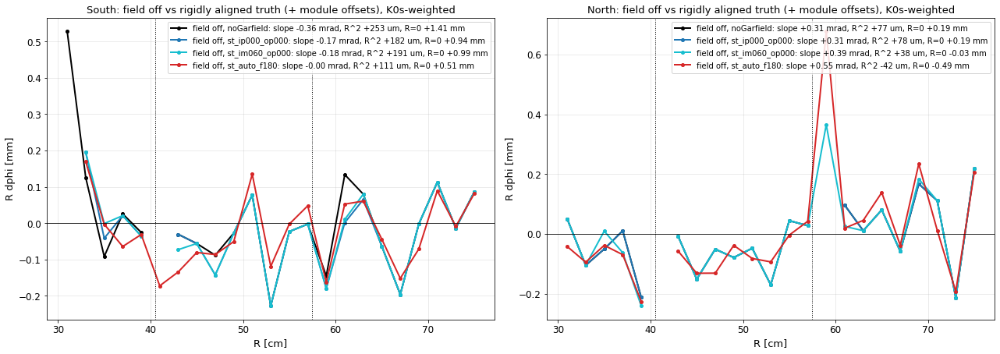

In [2]:
show(aq.fig_zf_alignment())

South +110 … +250 µm, North −40 … +80 µm of R² (range = the field-off correction used). The **full alignment** used from
here on subtracts, from raw field off (no PHGarfield correction: without B nothing moves in RΔφ), the 72 module
offsets and one common fine R profile (2 cm bins, φ-averaged) – it closes exactly in the φ average.

### 1a'. What the alignment is, step by step, and its values
1. **Rigid** CM → pad fit per side on field off, RΔφ only, sector edges excluded: rotation, dx, dy.
2. **72 pad modules** (12 sectors × R1/R2/R3 × 2 sides): median RΔφ per module after the rigid fit, ring mean removed.
3. **Common fine R profile**: median field-off RΔφ per 2 cm in R after steps 1–2 (φ-averaged): the stripe-row
   pattern (±0.2 mm) and the sharp inner-R1 rise in South (+0.6 mm at 31 cm). A coarser sector × 4 cm map (shown for
   its structure) averages that rise away and does not close (R² +157 / +85 µm left).

rigid CM -> pad alignment (field off 78242):
   South: rotation -2.03 mrad, dx -0.60 mm, dy +0.36 mm
   North: rotation -2.94 mrad, dx -0.34 mm, dy +0.06 mm


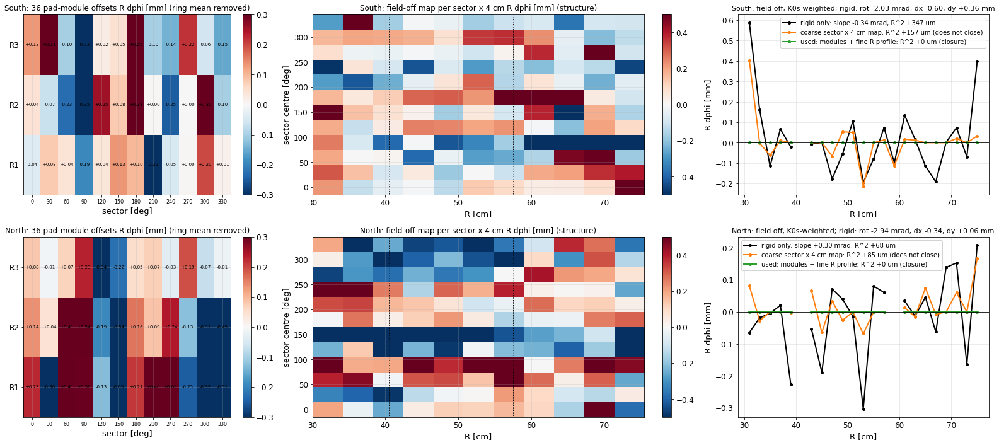

In [3]:
print('rigid CM -> pad alignment (field off 78242):')
for s, (rot, dx, dy) in cb.alignment_values().items():
    print(f"   {c.SIDES[s]:5s}: rotation {rot:+.2f} mrad, dx {dx:+.2f} mm, dy {dy:+.2f} mm")
show(cb.fig_alignment())

**Applying it at the pad plane.** Field off measures the CM pattern relative to the pads; it cannot tell which one moved.
If the CM stripes are where the drawing puts them, the 72 module offsets (up to ±0.3 mm) are pad-module positions and
can be applied to the clusters in local coordinates like a module alignment; the within-module stripe-row pattern
(±0.2 mm, period ~4 cm) looks like CM / pad-row geometry and should stay with the truth.

### 1b. Check against the tracks: K0s balance vs laser R² (795xx)
K0s: (⟨1/pT⁻⟩ − ⟨1/pT⁺⟩)/2 × 11.1 mm, cut03, mass 0.48–0.515 for every correction.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/alignqa.py:486: RuntimeWarning: Mean of empty slice
  return dec(np.nanmean([wprof(x) for x in xs], axis=0), ta.PRC)


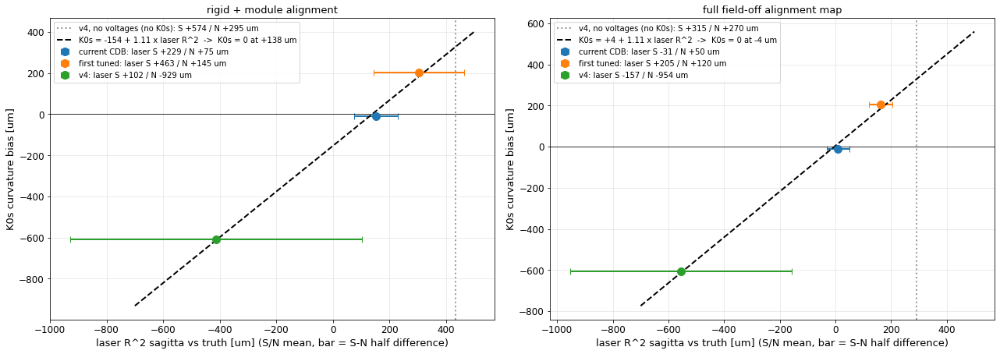

In [4]:
show(aq.fig_k0s_calibration())

With the full alignment: **K0s = +4 + 1.11 × laser R²** (residuals ≤ 25 µm, slope ≈ 1 as it must be): **K0s balance
0 ↔ laser R² ≈ 0** – a correction that matches the aligned CM truth gives balanced K0s. With only the rigid alignment
the zero was at +138 µm; with a PHGarfield-corrected field off as reference it is at +141 µm: the field-off R shape left
in the truth is why "better to the CM" made the tracks worse. (A 17 % N⁻/N⁺ at 2 GeV,
first tuned vs CDB, is ≈ 210 µm of sagitta: the falling spectrum amplifies it.)

### 1c. How good is the CDB, and is it kinky?

In [5]:
for s in (0, 1):
    d = cb.describe(cb.resid('cdb', s))
    print(f"CDB {c.SIDES[s]:5s}: R^2 {d['R2']:+5.0f} um, beyond-quad {d['beyond_quad']*1000:4.0f} um, steps at 40.5 / 57.5 cm {d['step1']:+.2f} / {d['step2']:+.2f} mm, pointing {d['pointing']:+.2f} mm")

CDB South: R^2   -31 um, beyond-quad  195 um, steps at 40.5 / 57.5 cm -0.17 / +0.28 mm, pointing +0.41 mm
CDB North: R^2   +50 um, beyond-quad  106 um, steps at 40.5 / 57.5 cm -0.31 / -0.13 mm, pointing +1.71 mm


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/calib.py:29: RuntimeWarning: Mean of empty slice
  _cache[k] = np.nanmean([aq.wprof(aq.full_aligned(r, ta.v4_tag(b, tag), s)) for r, b in aq.blocks(runs)], axis=0)


The CDB is on target within ±50 µm (South −31, North +50 µm; target 0) and **not kinky**: module-boundary steps
≤ 0.31 mm, beyond-quadratic 0.11–0.20 mm.

## 2. Space charge
### 2.1 keff vs the GEM current
A global fit of all 17 beam blocks per side: each block's static-only profile = static + keff_block × (the map's correction per
unit keff, measured on the same clusters). The keff each block wants, with the static per run period (its level per period is
not measured – only the slope inside a run is; keff(0) = 0 is assumed).

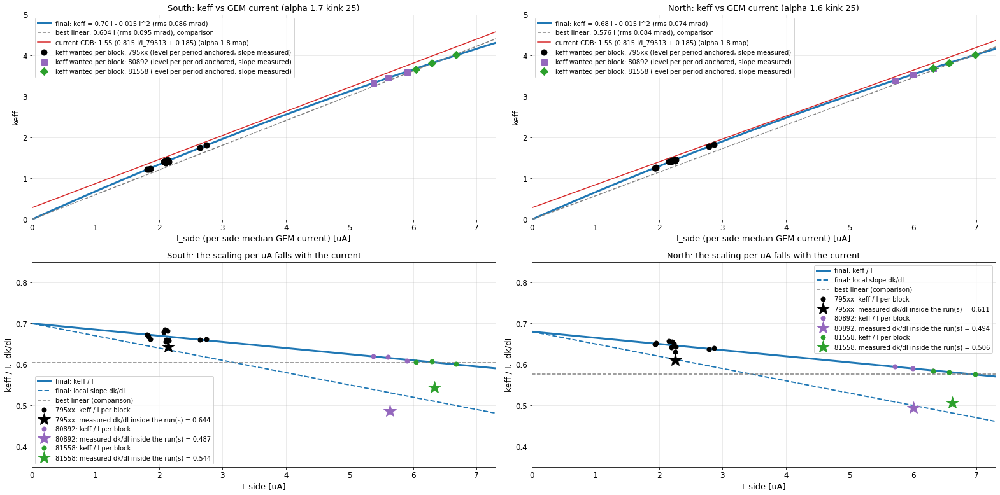

In [6]:
show(cf.fig_keff())

In [7]:
print(f"{'I [uA]':>7s} | {'final S':>8s} {'final N':>8s} | {'CDB S':>6s} {'CDB N':>6s} | {'keff/I S':>8s} {'dk/dI S':>8s}")
for I in (1, 2, 3, 4, 5, 6, 7):
    print(f"{I:7.1f} | {cf.k_final(0, I):8.3f} {cf.k_final(1, I):8.3f} | {cf.cdb_keff(0, I):6.2f} {cf.cdb_keff(1, I):6.2f} | {cf.k_final(0, I) / I:8.3f} {cf.A[0] - 2 * cf.CQ * I:8.3f}")

 I [uA] |  final S  final N |  CDB S  CDB N | keff/I S  dk/dI S
    1.0 |    0.685    0.665 |   0.87   0.85 |    0.685    0.670
    2.0 |    1.340    1.300 |   1.46   1.40 |    0.670    0.640
    3.0 |    1.965    1.905 |   2.05   1.96 |    0.655    0.610
    4.0 |    2.560    2.480 |   2.64   2.52 |    0.640    0.580
    5.0 |    3.125    3.025 |   3.23   3.08 |    0.625    0.550
    6.0 |    3.660    3.540 |   3.81   3.64 |    0.610    0.520
    7.0 |    4.165    4.025 |   4.40   4.20 |    0.595    0.490


- Inside 795xx (≈ 2 µA) a block-to-block current change needs dk/dI ≈ 0.64 (S) / 0.61 (N); inside 80892 / 81558 (≈ 6 µA)
  only 0.49–0.54 / 0.49–0.51. The final curve (solid) gives exactly these slopes (dashed in the lower panels).
- The CDB (red; its own α 1.8 map, so its scale is not directly comparable) has an offset at I = 0 and a constant slope.
### 2.2 keff QA: how much curvature, where in R, what is left

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/calfinal.py:90: RuntimeWarning: Mean of empty slice
  P0, U = d3.unit_response(s, 'v8'); Um = np.nanmean(U, axis=0)


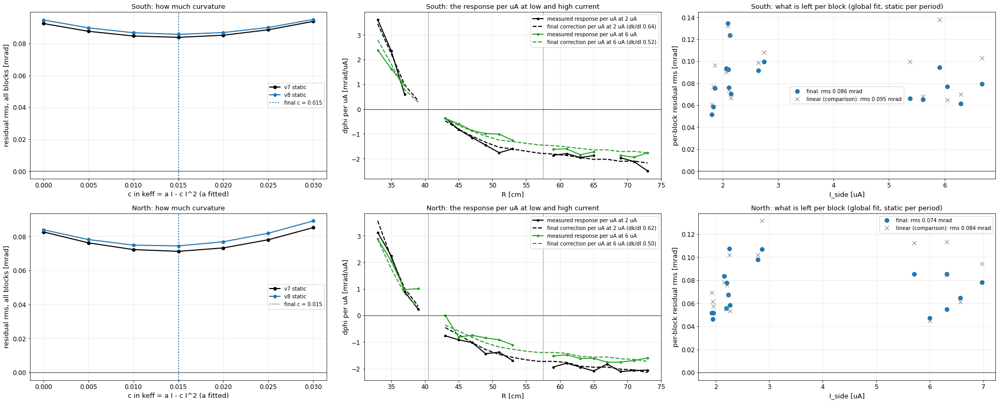

In [8]:
show(cf.fig_keff_qa())

- Left: c = 0.015 minimises the residual of all blocks (v7 and v8 statics, both sides); c = 0 (linear) is clearly worse.
- Middle: model-free, the measured response per µA at 2 and 6 µA (fit P = S + I A(R) + I² B(R) per R) vs what the final
  correction removes per µA there: both scale down by ≈ 20 % at 6 µA.
- Right: per-block residual: final vs linear.

### 2.3 Every current difference: final calibration vs the CDB
Black = measured change (final static, no space charge); blue = what the final calibration leaves; red = what the CDB leaves;
grey dotted = linear keff (comparison). The static is the same correction in every run, so it cancels.
#### Absolute dφ vs R per run (own-period static)

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v9ana.py:10: RuntimeWarning: Mean of empty slice
  P = np.nanmean([k8.bp(tag, r, k, s, col) for r, k in bl], axis=0)


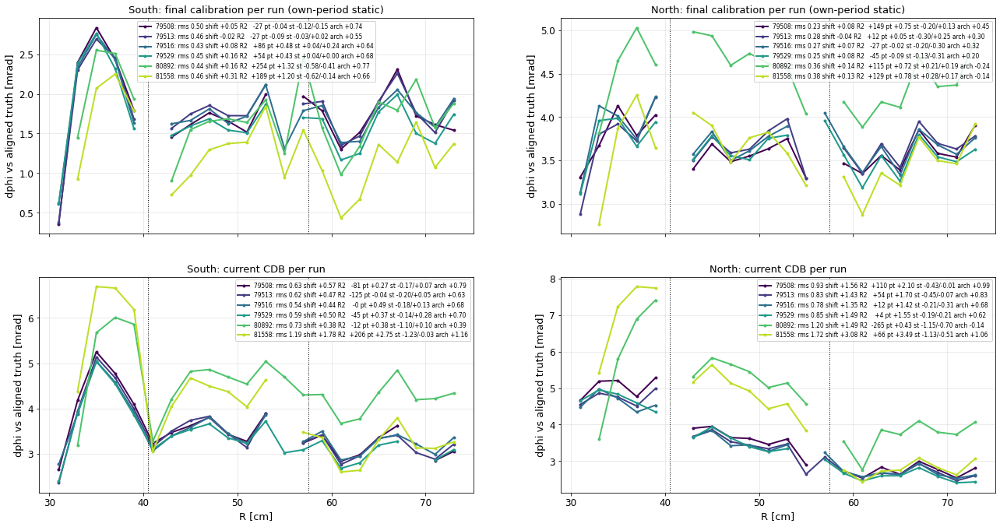

In [9]:
show(v9.fig_runs())

#### South: run − run, raw [mrad]

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/scqa.py:333: RuntimeWarning: Mean of empty slice
  _c[key] = np.nanmean(P, axis=0) if P else np.full(len(R), np.nan)


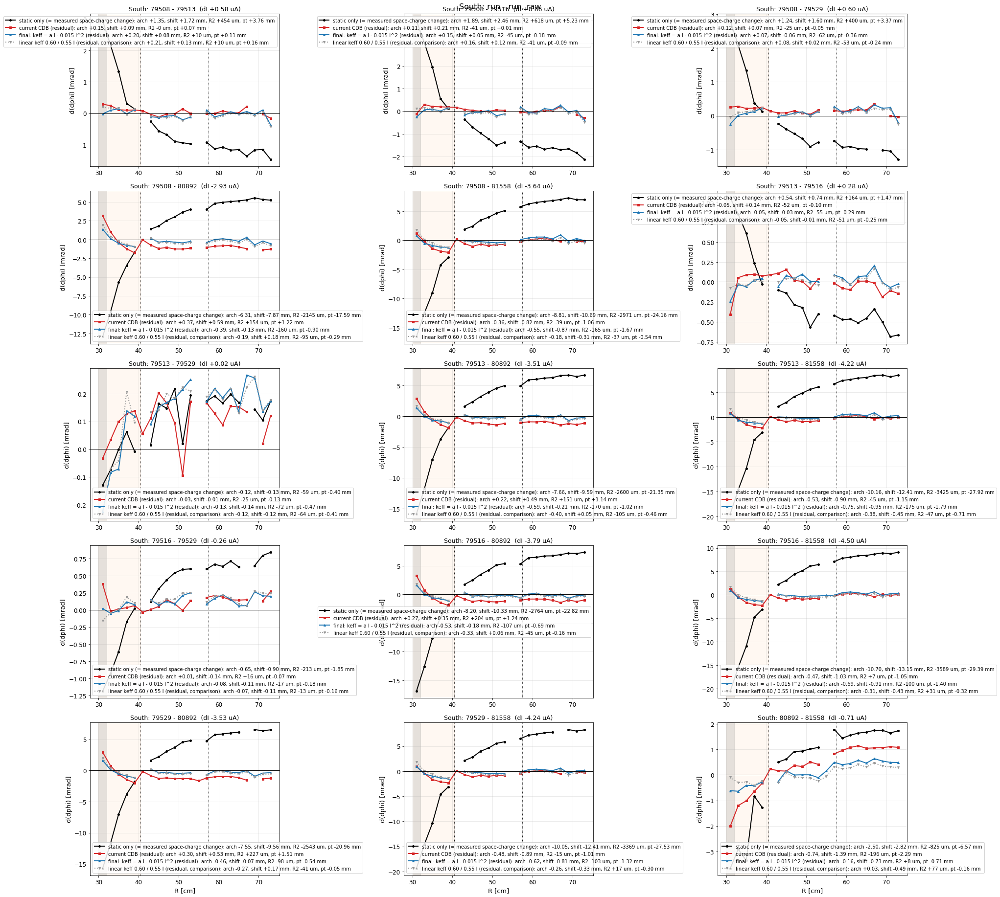

In [10]:
show(q.fig_run_diffs(0, cf.CFG, title='South: run - run, raw'))

#### South: run − run per µA

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


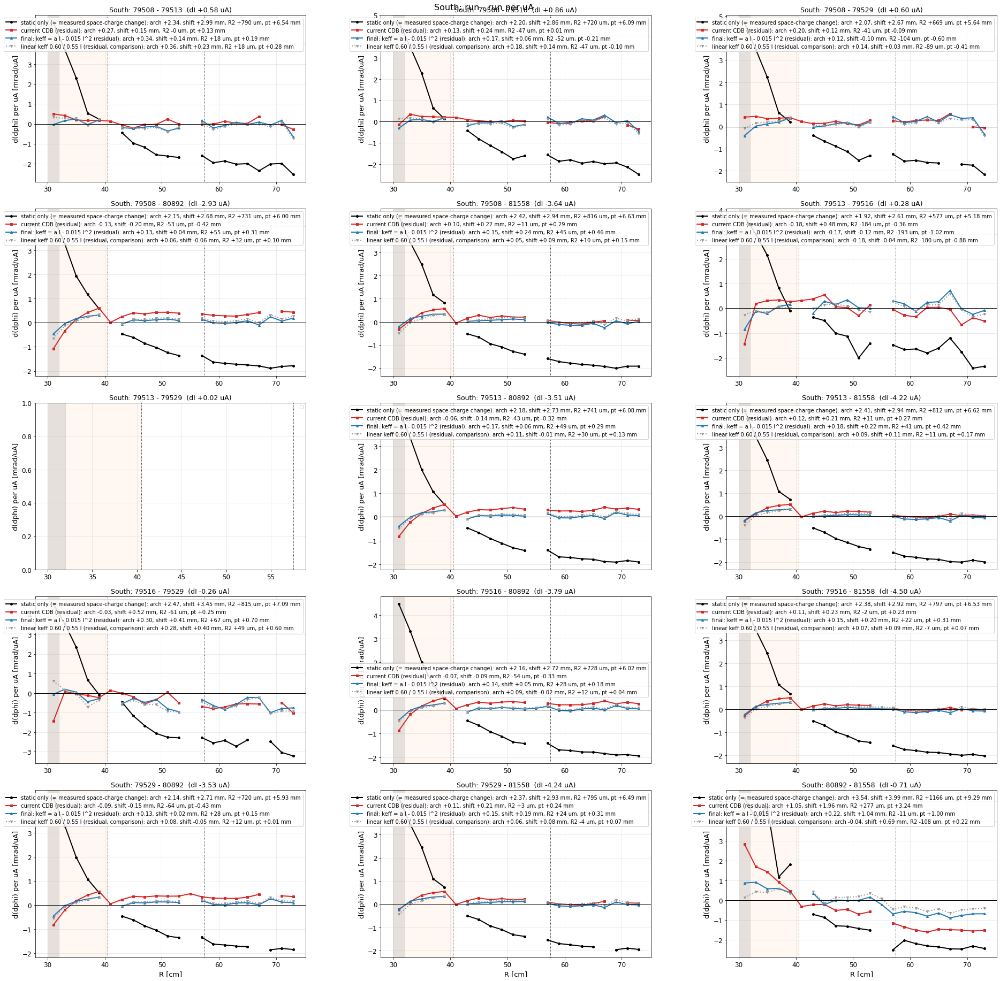

In [11]:
show(q.fig_run_diffs(0, cf.CFG, per_uA=True, title='South: run - run per uA'))

#### North: run − run, raw [mrad]

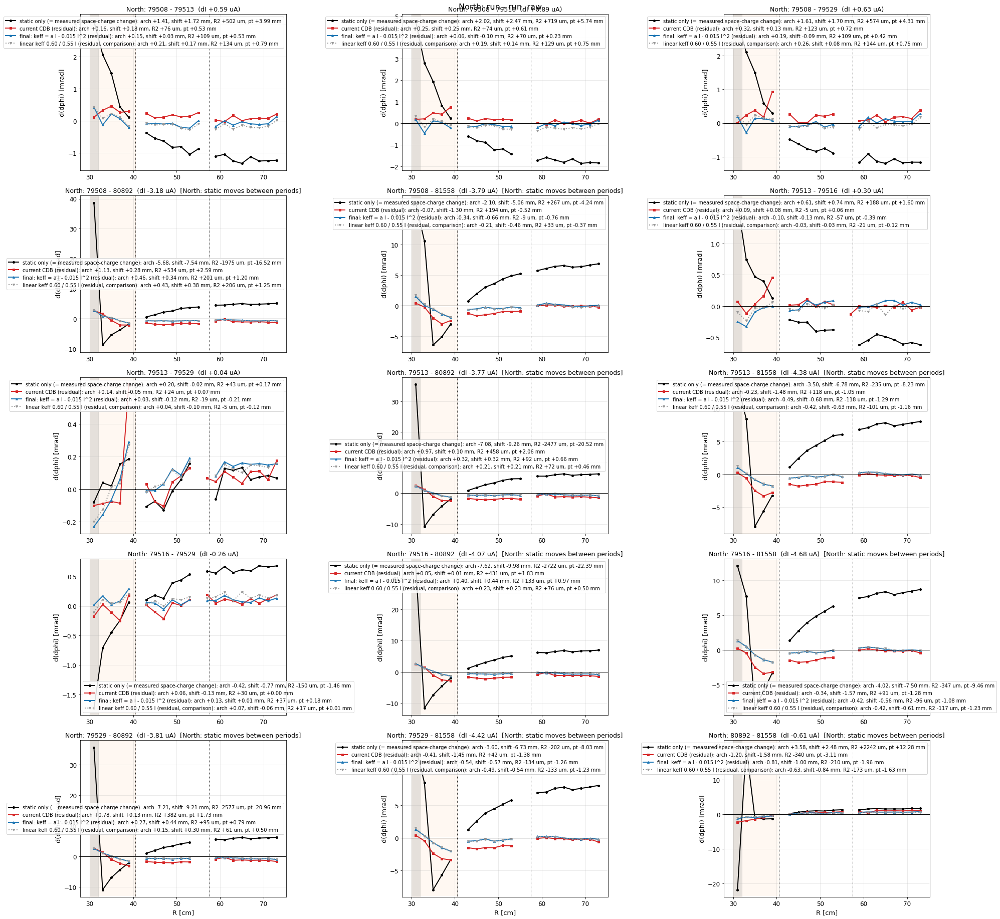

In [12]:
show(q.fig_run_diffs(1, cf.CFG, title='North: run - run, raw'))

#### North: run − run per µA

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


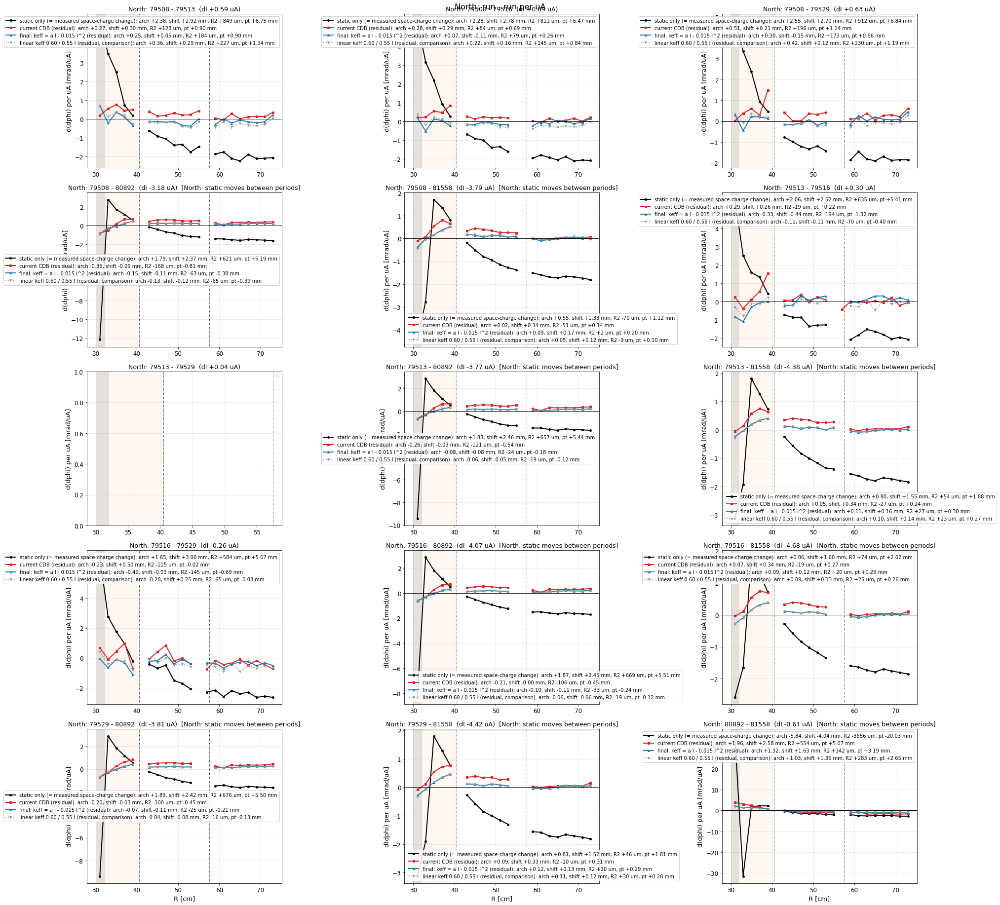

In [13]:
show(q.fig_run_diffs(1, cf.CFG, per_uA=True, title='North: run - run per uA'))

#### Key pairs in four φ bins

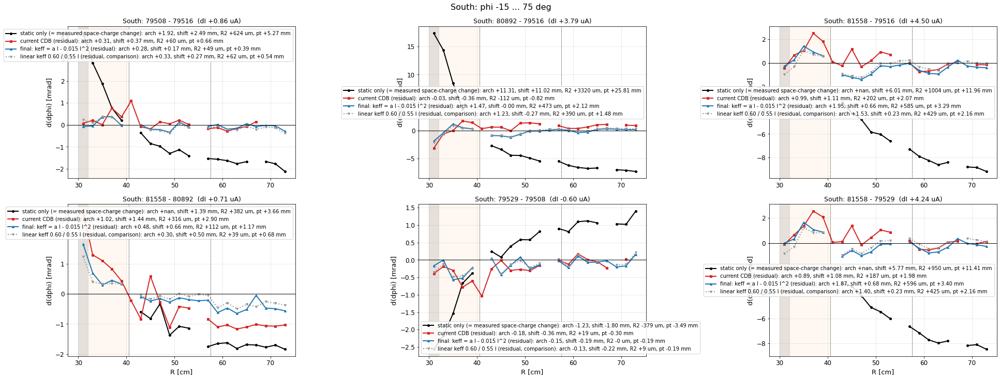

In [14]:
show(q.fig_run_diffs(0, cf.CFG, pairs_=[('79508', '79516'), ('80892', '79516'), ('81558', '79516'), ('81558', '80892'), ('79529', '79508'), ('81558', '79529')], phi=(-15, 75), title='South: phi -15 ... 75 deg'))

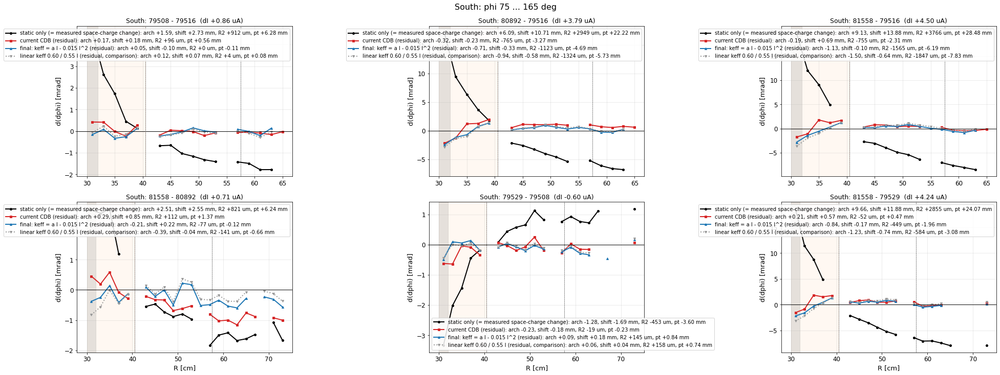

In [15]:
show(q.fig_run_diffs(0, cf.CFG, pairs_=[('79508', '79516'), ('80892', '79516'), ('81558', '79516'), ('81558', '80892'), ('79529', '79508'), ('81558', '79529')], phi=(75, 165), title='South: phi 75 ... 165 deg'))

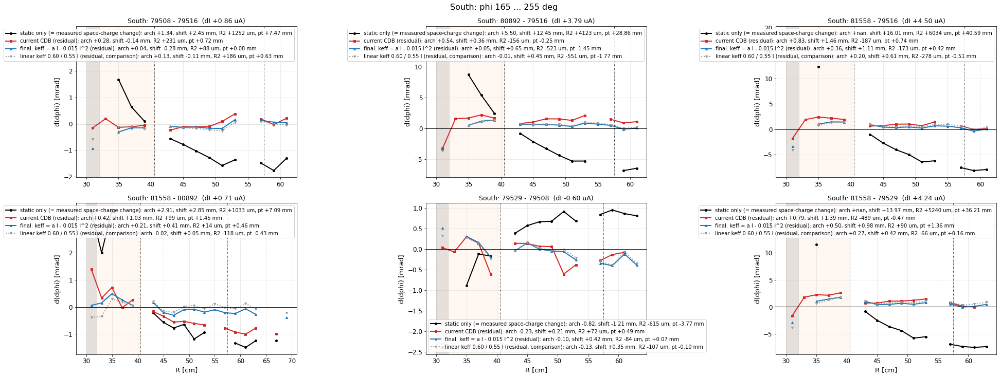

In [16]:
show(q.fig_run_diffs(0, cf.CFG, pairs_=[('79508', '79516'), ('80892', '79516'), ('81558', '79516'), ('81558', '80892'), ('79529', '79508'), ('81558', '79529')], phi=(165, 255), title='South: phi 165 ... 255 deg'))

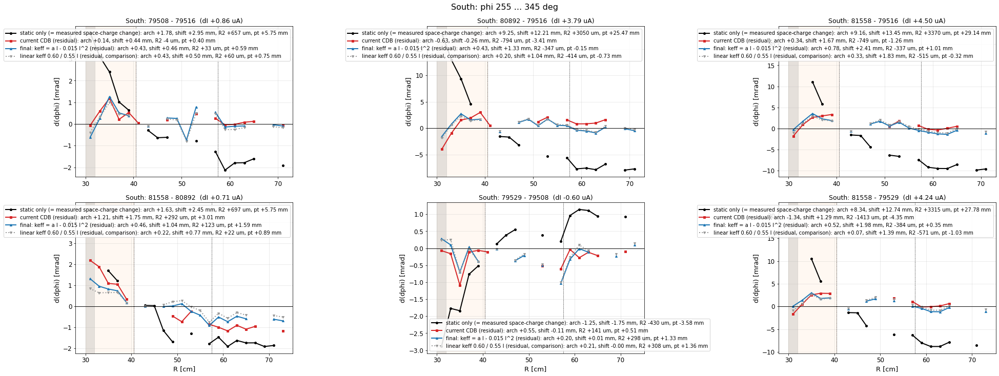

In [17]:
show(q.fig_run_diffs(0, cf.CFG, pairs_=[('79508', '79516'), ('80892', '79516'), ('81558', '79516'), ('81558', '80892'), ('79529', '79508'), ('81558', '79529')], phi=(255, 345), title='South: phi 255 ... 345 deg'))

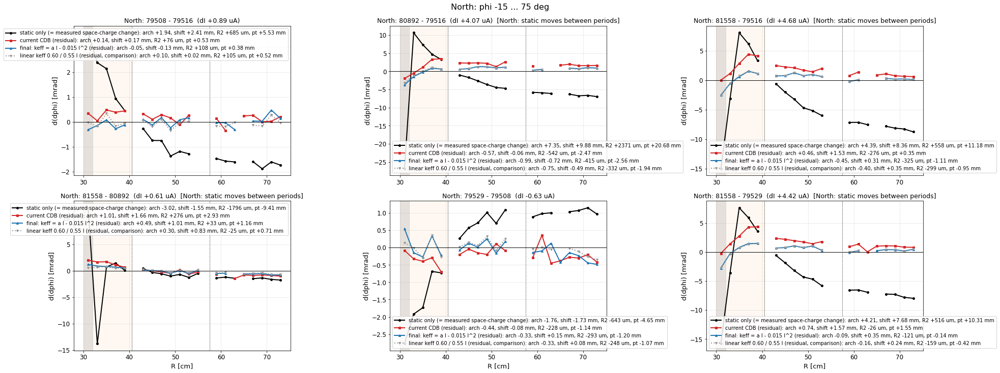

In [18]:
show(q.fig_run_diffs(1, cf.CFG, pairs_=[('79508', '79516'), ('80892', '79516'), ('81558', '79516'), ('81558', '80892'), ('79529', '79508'), ('81558', '79529')], phi=(-15, 75), title='North: phi -15 ... 75 deg'))

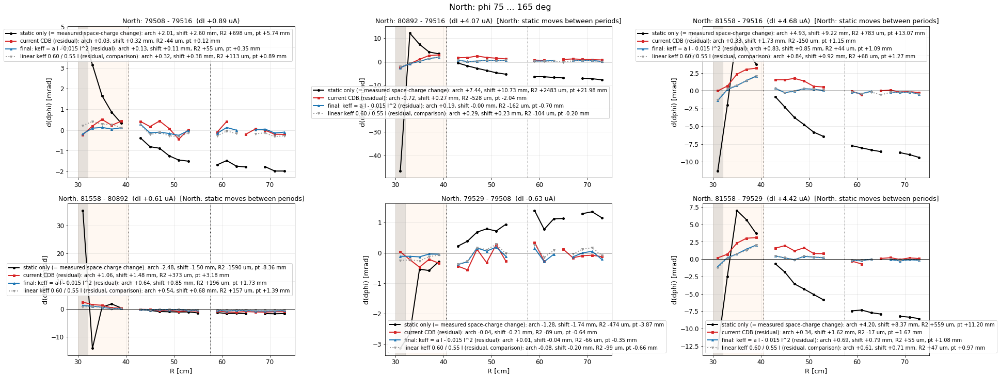

In [19]:
show(q.fig_run_diffs(1, cf.CFG, pairs_=[('79508', '79516'), ('80892', '79516'), ('81558', '79516'), ('81558', '80892'), ('79529', '79508'), ('81558', '79529')], phi=(75, 165), title='North: phi 75 ... 165 deg'))

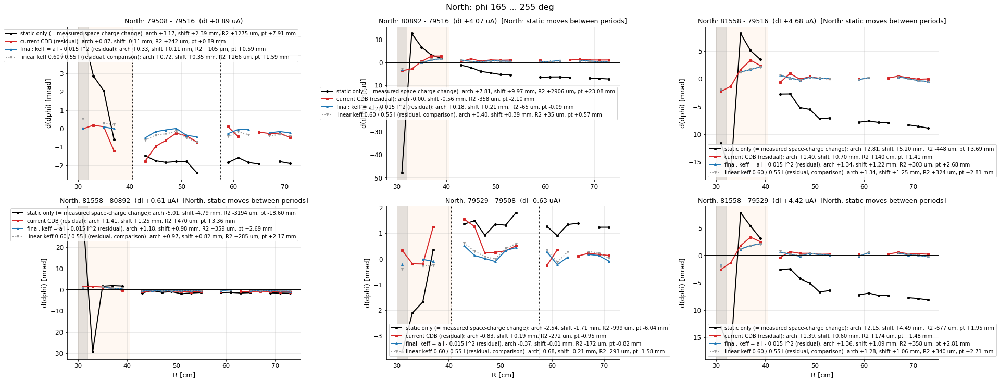

In [20]:
show(q.fig_run_diffs(1, cf.CFG, pairs_=[('79508', '79516'), ('80892', '79516'), ('81558', '79516'), ('81558', '80892'), ('79529', '79508'), ('81558', '79529')], phi=(165, 255), title='North: phi 165 ... 255 deg'))

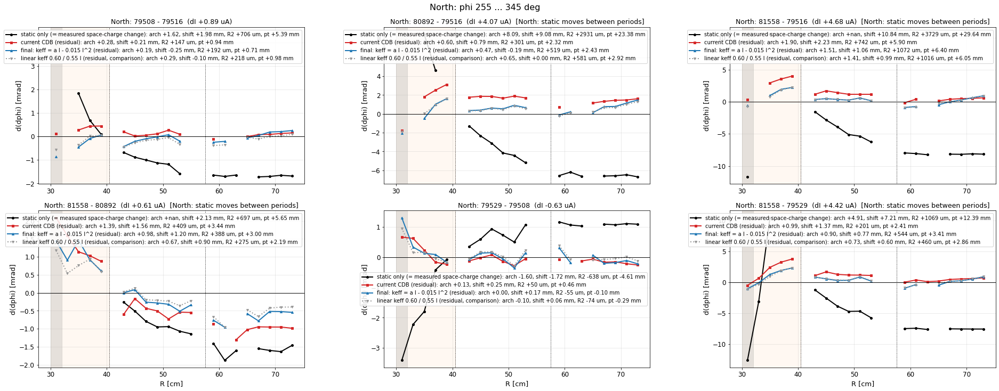

In [21]:
show(q.fig_run_diffs(1, cf.CFG, pairs_=[('79508', '79516'), ('80892', '79516'), ('81558', '79516'), ('81558', '80892'), ('79529', '79508'), ('81558', '79529')], phi=(255, 345), title='North: phi 255 ... 345 deg'))

#### Inside each run: first block − last block (same fill)

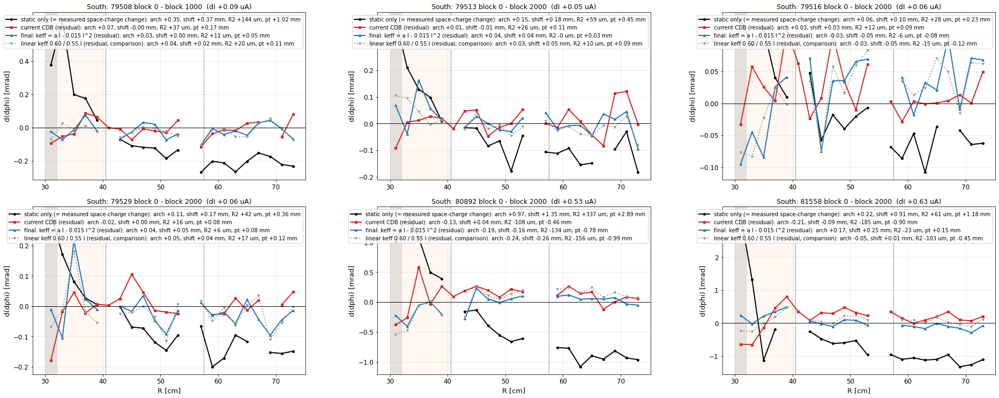

In [22]:
show(q.fig_block_diffs(0, cf.CFG))

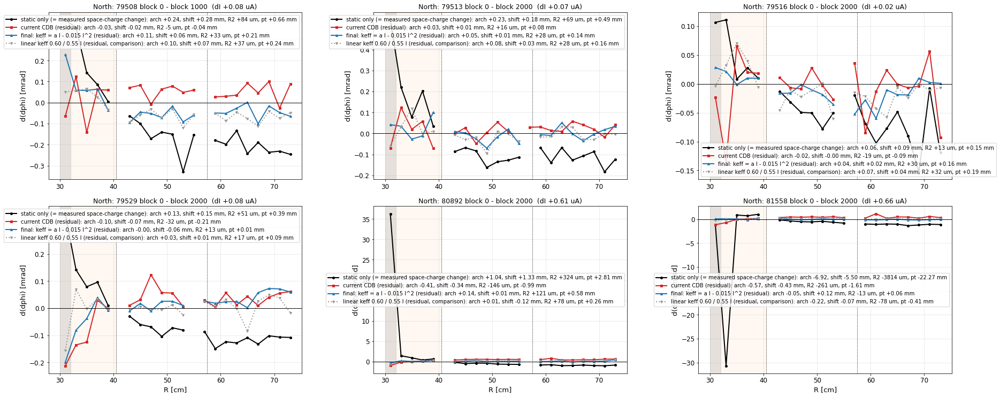

In [23]:
show(q.fig_block_diffs(1, cf.CFG))

#### Every block − 79516, coloured by the current: static only, final, CDB

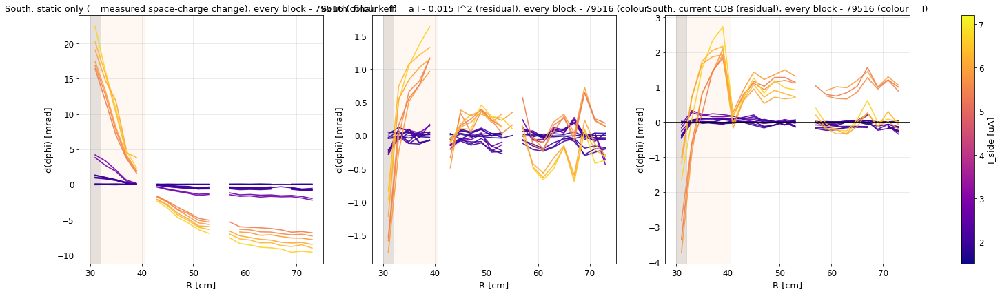

In [24]:
show(q.fig_diff_vs_I(0, [cf.CFG[0], cf.CFG[2], cf.CFG[1]]))

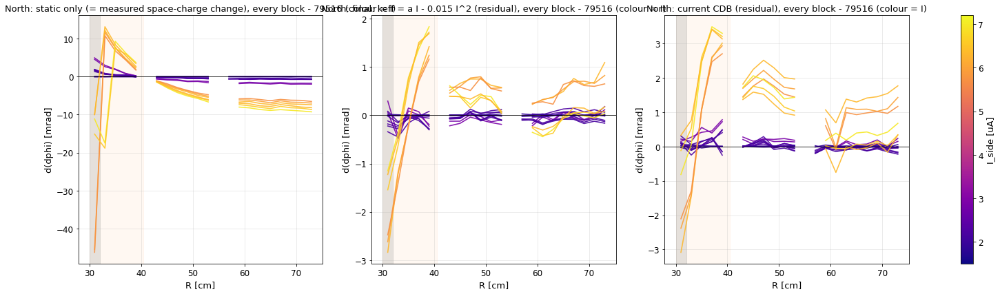

In [25]:
show(q.fig_diff_vs_I(1, [cf.CFG[0], cf.CFG[2], cf.CFG[1]]))

#### R1 arch, sideways shift, R², pointing per block vs I (absolute; final with the own-period static)

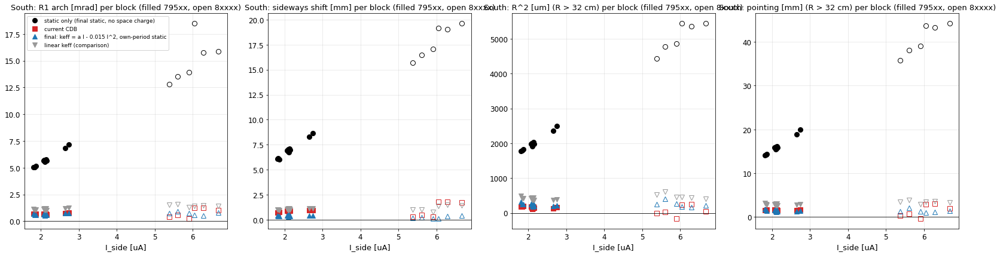

In [26]:
show(cf.fig_quantities_vs_I(0))

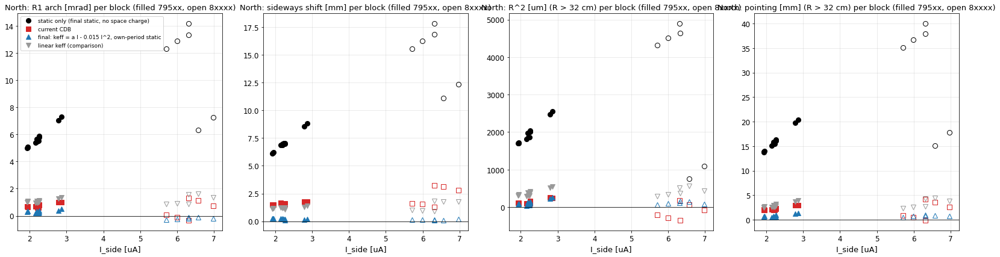

In [27]:
show(cf.fig_quantities_vs_I(1))

### 2.4 Which map (each with the quadratic keff, its own a)
Every map of the v7 scan applied with keff = a I − 0.015 I² by superposition (static cancels); a fitted per map.

In [28]:
for side, lab, a, rms in cf.map_table():
    print(f"{side:5s} {lab:24s} a {a:.3f}  residual rms of all blocks {rms:.4f} mrad")

South alpha 1.8 kink 22.75     a 0.736  residual rms of all blocks 0.0941 mrad
South alpha 1.8 kink 23.90     a 0.722  residual rms of all blocks 0.0882 mrad
South alpha 1.8 kink 25.00     a 0.707  residual rms of all blocks 0.0870 mrad
South alpha 1.8 kink 26.25     a 0.677  residual rms of all blocks 0.0848 mrad
South alpha 1.8 kink 27.50     a 0.650  residual rms of all blocks 0.0924 mrad
South alpha 1.6 kink 23.90     a 0.713  residual rms of all blocks 0.0868 mrad
South alpha 1.6 kink 25.00     a 0.703  residual rms of all blocks 0.0853 mrad
South alpha 1.6 kink 26.25     a 0.673  residual rms of all blocks 0.0895 mrad
South alpha 1.7 kink 25.00     a 0.705  residual rms of all blocks 0.0839 mrad
North alpha 1.8 kink 22.75     a 0.716  residual rms of all blocks 0.0831 mrad
North alpha 1.8 kink 23.90     a 0.698  residual rms of all blocks 0.0783 mrad
North alpha 1.8 kink 25.00     a 0.682  residual rms of all blocks 0.0757 mrad
North alpha 1.8 kink 26.25     a 0.659  residual rms

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/calfinal.py:125: RuntimeWarning: Mean of empty slice
  return np.nanmean(P, axis=0)


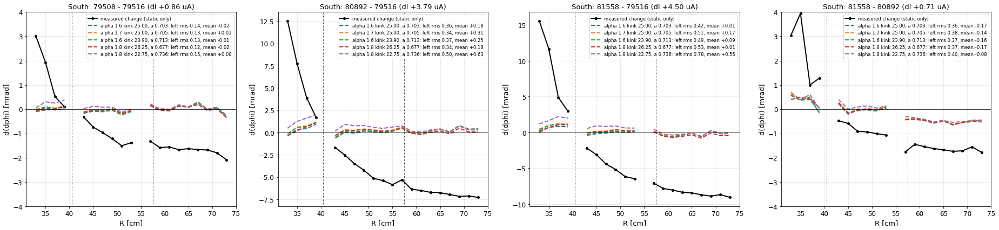

In [29]:
show(cf.fig_map_pairs(0))

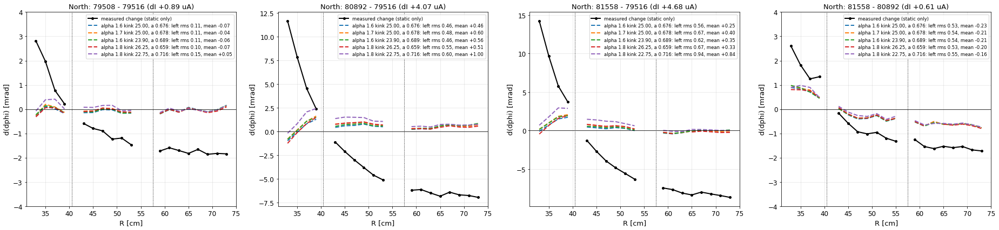

In [30]:
show(cf.fig_map_pairs(1))

- South: α 1.7 kink 25 best (0.084), α 1.6 kink 25 / α 1.8 kink 26.25 within 0.001; North: α 1.8 kink 26.25 / α 1.6 kink 23.9–25
  (0.073). α 1.8 kink 22.75 (the CDB shape) worst on both sides. The CM does not resolve the profile further (kink below 30 cm).

### 2.5 The static changes between run periods

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/static7.py:53: RuntimeWarning: Mean of empty slice
  P = np.nanmean(P, axis=0) if P else np.full(len(R), np.nan)


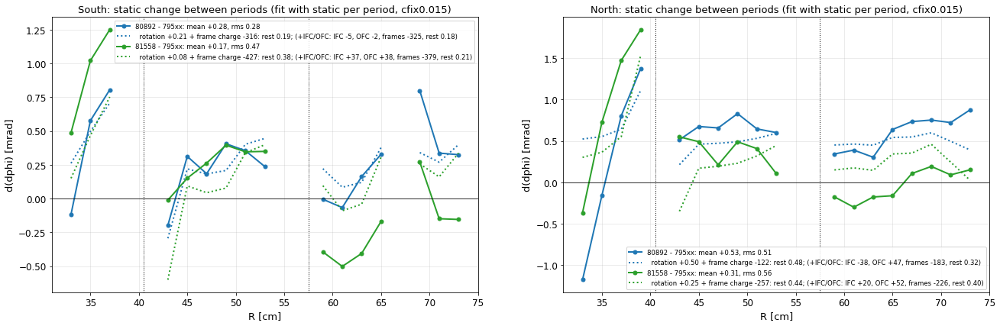

In [31]:
show(d3.fig_period_static('v8', 'cfix0.015'))

### 2.6 3D: the space-charge scale per pad module
Per sector and 4-cm R bin: g = data scale / map scale with the final keff (jackknife errors over the six runs).

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/sc3d.py:331: RuntimeWarning: Mean of empty slice
  err = np.sqrt((n - 1) / n * np.nansum((J - np.nanmean(J, axis=0)) ** 2, axis=0))
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/sc3d.py:346: RuntimeWarning: All-NaN slice encountered
  axs[s, 2].plot(R4, np.nanmedian(RES0, axis=0), 'k-o', label='phi-integrated keff only (g = 1)')
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/sc3d.py:347: RuntimeWarning: All-NaN slice encountered
  axs[s, 2].plot(R4, np.nanmedian(RES, axis=0), 'b-s', label='with g per sector x R')


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/sc3d.py:346: RuntimeWarning: All-NaN slice encountered
  axs[s, 2].plot(R4, np.nanmedian(RES0, axis=0), 'k-o', label='phi-integrated keff only (g = 1)')
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/sc3d.py:347: RuntimeWarning: All-NaN slice encountered
  axs[s, 2].plot(R4, np.nanmedian(RES, axis=0), 'b-s', label='with g per sector x R')


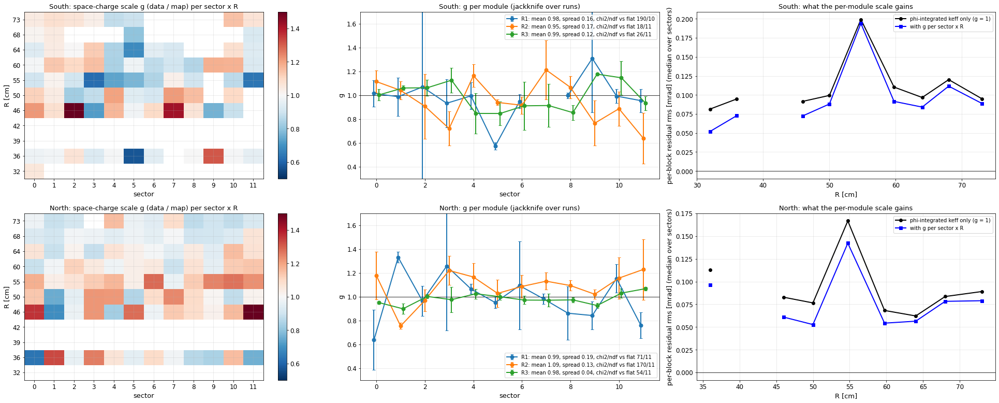

In [32]:
show(d3.fig_gain_err('v8', 'cfix0.015'))

In [33]:
for s in (0, 1):
    MG, err, G, RES, RES0 = d3.gain_jackknife(s, 'v8', 'cfix0.015')
    for j, nm in enumerate(('R1', 'R2', 'R3')):
        print(f"{c.SIDES[s]} {nm}: " + ' '.join(f"{x:.2f}+-{e:.2f}" for x, e in zip(MG[:, j], err[:, j])))

South R1: 1.01+-0.11 0.99+-0.16 1.07+-0.85 0.93+-0.20 0.99+-0.11 0.57+-0.03 0.95+-0.06 nan+-0.00 1.00+-0.02 1.31+-0.45 0.99+-0.06 0.95+-0.10
South R2: 1.11+-0.09 1.04+-0.07 0.91+-0.27 0.72+-0.14 1.16+-0.10 0.94+-0.02 0.92+-0.07 1.21+-0.25 1.07+-0.09 0.77+-0.19 0.89+-0.14 0.64+-0.21
South R3: 1.00+-0.05 1.06+-0.02 1.06+-0.07 1.13+-0.10 0.85+-0.17 0.85+-0.10 0.91+-0.20 0.91+-0.18 0.85+-0.06 1.18+-0.00 1.15+-0.14 0.93+-0.06
North R1: 0.64+-0.25 1.33+-0.05 0.96+-0.12 1.26+-0.54 1.07+-0.04 0.95+-0.05 1.09+-0.37 0.98+-0.04 0.86+-0.22 0.84+-0.12 1.15+-0.12 0.76+-0.11
North R2: 1.18+-0.20 0.75+-0.03 0.97+-0.09 1.22+-0.12 1.17+-0.11 1.03+-0.12 1.09+-0.10 1.13+-0.07 1.09+-0.04 1.02+-0.04 1.16+-0.17 1.23+-0.25
North R3: 0.95+-0.01 0.90+-0.04 1.00+-0.02 0.98+-0.11 1.02+-0.04 1.00+-0.03 0.97+-0.03 0.97+-0.05 0.97+-0.02 0.93+-0.02 1.03+-0.04 1.07+-0.02


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/sc3d.py:331: RuntimeWarning: Mean of empty slice
  err = np.sqrt((n - 1) / n * np.nansum((J - np.nanmean(J, axis=0)) ** 2, axis=0))


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/sc3d.py:316: RuntimeWarning: Mean of empty slice
  axs[i].plot(R4, lin * np.nanmean(U[:, i], axis=0), '--', color='tab:green', lw=2, label=f'map x b {lin:.2f}')


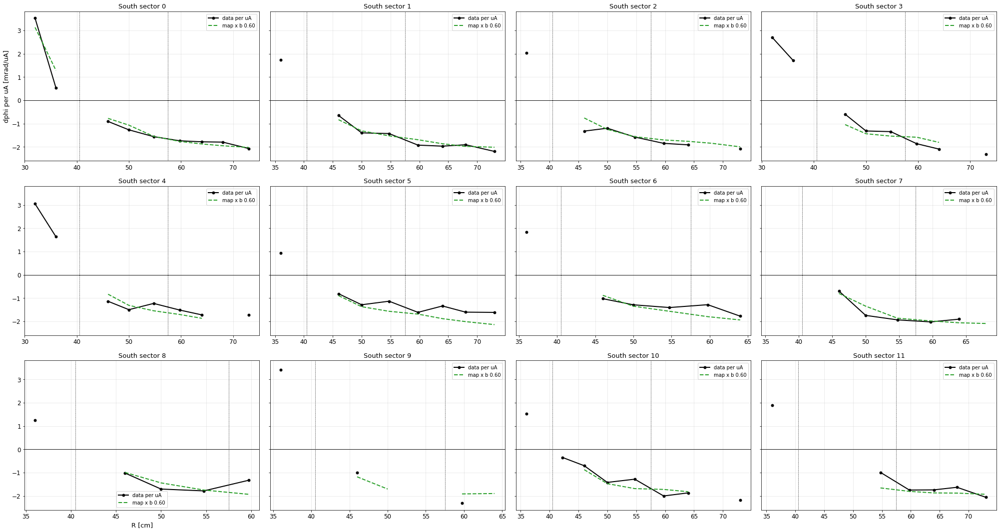

In [34]:
show(d3.fig_sector_response(0, 'v8'))

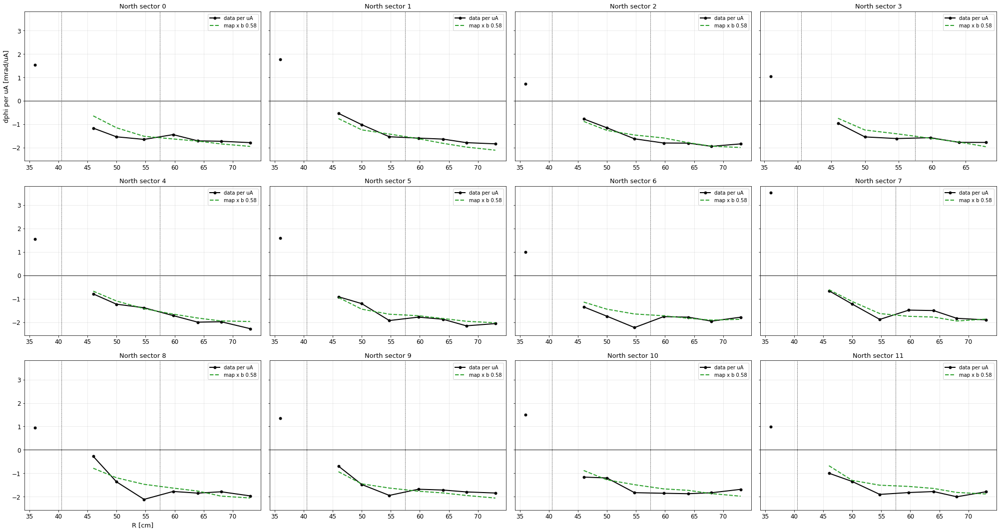

In [35]:
show(d3.fig_sector_response(1, 'v8'))

Significant outliers: South R1 sector 5 (≈ 0.6), South R2 sector 11 (≈ 0.7), North R1 sector 1 (≈ 1.3), North R2 sector 1 (≈ 0.75);
North R3 uniform. With g per module the per-block residual drops ≈ 15 %: to go into the density map as per-module weights.

### 2.7 Which GEM current

In [36]:
for r, sr1, sm, rs, nr1, nm, rn in q.run_current_table():
    print(f"{r}: SR1 {sr1:.2f}  SOUTH {sm:.2f}  R1/med {rs:.3f}  |  NR1 {nr1:.2f}  NORTH {nm:.2f}  R1/med {rn:.3f}")
for s in (0, 1):
    rows, ws, rr = q.current_test(s)
    print(c.SIDES[s], ' | '.join(f'{k} {x:.3f}' for k, x in rows.items()), f'| best R1 weight {ws[int(np.argmin(rr))]:+.2f}')

79508: SR1 4.31  SOUTH 2.65  R1/med 1.626  |  NR1 4.22  NORTH 2.79  R1/med 1.510
79513: SR1 3.36  SOUTH 2.09  R1/med 1.608  |  NR1 3.20  NORTH 2.22  R1/med 1.445
79516: SR1 2.93  SOUTH 1.83  R1/med 1.606  |  NR1 2.78  NORTH 1.92  R1/med 1.448
79529: SR1 3.39  SOUTH 2.07  R1/med 1.637  |  NR1 3.17  NORTH 2.18  R1/med 1.456
80892: SR1 9.65  SOUTH 5.50  R1/med 1.755  |  NR1 9.19  NORTH 5.83  R1/med 1.575
81558: SR1 9.96  SOUTH 6.04  R1/med 1.647  |  NR1 9.45  NORTH 6.34  R1/med 1.490
South median, linear 0.238 | median, quadratic 0.201 | R1, linear 0.400 | R1, quadratic 0.384 | best R1 weight -0.50
North median, linear 0.111 | median, quadratic 0.079 | R1, linear 0.109 | R1, quadratic 0.085 | best R1 weight +0.55


The per-side median current (used) describes the block-to-block change clearly better than the R1 current.

## 3. Static with the final space charge
The knobs (inner / outer field-cage voltage, module-frame charge, an R1-only frame weight) were varied on every block (v8);
with the final keff they are fitted per period: dφ flat, R² = 0 (K0s balance 0), pointing and shift 0, flat steps.

- North R3 is uniform (g spread 0.05, errors 0.01–0.06); R1 and R2 vary by 0.13–0.2 between sectors. Significant outliers
  (jackknife): South R1 sector 5 0.59 ± 0.04, South R2 sector 11 0.67 ± 0.09, North R1 sector 1 1.31 ± 0.06, North R2
  sector 1 0.75 ± 0.07; others (North R1 sectors 0 / 3 / 6) have errors 0.2–0.6 – per-module GEM gain × IBF.
- With g per module the per-block residual drops ≈ 15 % (0.09 → 0.08 mrad): worth including in the density map (per-module
  weights) once the errors confirm the outliers; it is not what limits the φ-integrated correction.

### 3.6 The static per period on v8, with keff = a I − 0.015 I²
Knob responses per period (per +20 V IFC / OFC, +30 frame charge, +1 in R1 frame weight):

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/cal8.py:74: RuntimeWarning: Mean of empty slice
  return np.nanmean(P, axis=0)


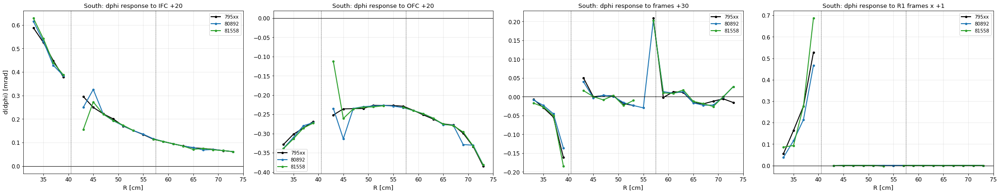

In [37]:
show(k8.fig_responses(0))

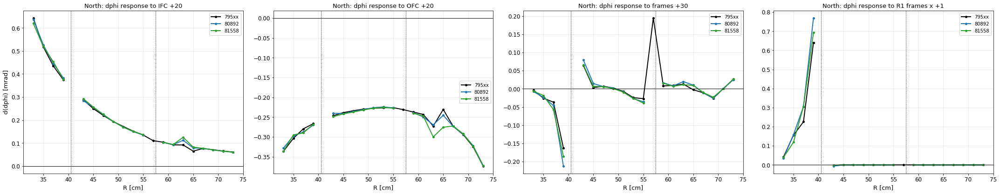

In [38]:
show(k8.fig_responses(1))

Fits: IFC, OFC, frame charge per period (joint objective: dφ flat, R² / pointing / shift on target, flat steps, small
changes). 795xx with all bins (K0s-calibrated R² = 0); every period also with R > 32 cm, whose R² / pointing targets
are the values of the 795xx all-bin solution in that metric. Also: frames only; and with the R1 frame weight.

In [39]:
for s in (0, 1):
    for knobs in (('IFC', 'OFC', 'frames'), ('frames',), ('IFC', 'OFC', 'frames', 'R1 frames x')):
        tg, sols = k8.solutions(s, knobs=knobs)
        print(f"{c.SIDES[s]} knobs {knobs}: targets (R > 32 metric) R2 {tg['R2']:+.0f} um, pointing {tg['pointing']:+.2f}, shift {tg['shift']:+.2f}")
        for lab, o in sols:
            dd = o['d']; ab = lambda n, b: f"{b + dd[n]:+5.0f}" if n in dd else '    -'
            print(f"   {lab:30s} IFC {ab('IFC', k8.BASE['ifc'][s])} OFC {ab('OFC', k8.BASE['ofc'][s])} frames {ab('frames', k8.BASE['frame'][s])}" + (f" R1 x{1 + dd['R1 frames x']:.2f}" if 'R1 frames x' in dd else '') + ' | ' + qline(o['Q']))
    for nm, runs in k8.PER:
        Cp, Cr = k8.cdb_period(s, runs); print(f"   CDB {nm:26s} " + qline(k8.quantities(Cp, Cr)))
    print()

South knobs ('IFC', 'OFC', 'frames'): targets (R > 32 metric) R2 +221 um, pointing +1.33, shift +0.34
   795xx (all bins, K0s metric)   IFC    -4 OFC    +4 frames  -157 | dphi rms 0.46 mrad, shift -0.01 mm, R2    +1 um, pointing +0.03 mm, steps +0.02 / -0.02 mm, R1 arch +0.58 mrad
   795xx (R > 32)                 IFC   -17 OFC    -4 frames  -163 | dphi rms 0.31 mrad, shift +0.14 mm, R2  +228 um, pointing +1.16 mm, steps -0.01 / +0.01 mm, R1 arch +0.52 mrad
   80892 (R > 32)                 IFC   -26 OFC   +14 frames  -108 | dphi rms 0.44 mrad, shift +0.09 mm, R2  +232 um, pointing +1.15 mm, steps -0.51 / -0.40 mm, R1 arch +0.69 mrad
   81558 (R > 32)                 IFC   -66 OFC    +7 frames  -149 | dphi rms 0.45 mrad, shift +0.18 mm, R2  +137 um, pointing +0.83 mm, steps -0.56 / -0.34 mm, R1 arch +0.54 mrad
South knobs ('frames',): targets (R > 32 metric) R2 +101 um, pointing +0.11, shift -0.34
   795xx (all bins, K0s metric)   IFC     - OFC     - frames  -207 | dphi rms 0.67 mrad, 

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/cal8.py:173: RuntimeWarning: Mean of empty slice
  Pp = np.nanmean([bp('cdb', r, k, s, 5) for r, k, I in blocks(runs)], axis=0); Pr = np.nanmean([bp('cdb', r, k, s, 4) for r, k, I in blocks(runs)], axis=0)


North knobs ('IFC', 'OFC', 'frames'): targets (R > 32 metric) R2 +85 um, pointing +0.53, shift +0.15
   795xx (all bins, K0s metric)   IFC   -43 OFC    -6 frames  -182 | dphi rms 0.25 mrad, shift +0.01 mm, R2    -6 um, pointing -0.01 mm, steps -0.19 / -0.21 mm, R1 arch +0.25 mrad
   795xx (R > 32)                 IFC   -48 OFC    -9 frames  -185 | dphi rms 0.21 mrad, shift +0.07 mm, R2   +82 um, pointing +0.43 mm, steps -0.20 / -0.20 mm, R1 arch +0.22 mrad
   80892 (R > 32)                 IFC   -11 OFC    -9 frames   -27 | dphi rms 0.37 mrad, shift +0.07 mm, R2   +82 um, pointing +0.52 mm, steps -0.04 / +0.14 mm, R1 arch -0.20 mrad
   81558 (R > 32)                 IFC   -70 OFC    -5 frames    -9 | dphi rms 0.44 mrad, shift +0.08 mm, R2   +88 um, pointing +0.53 mm, steps -0.03 / +0.11 mm, R1 arch -0.07 mrad
North knobs ('frames',): targets (R > 32 metric) R2 -174 um, pointing -1.70, shift -0.91
   795xx (all bins, K0s metric)   IFC     - OFC     - frames  -240 | dphi rms 0.74 mrad, s

North knobs ('IFC', 'OFC', 'frames', 'R1 frames x'): targets (R > 32 metric) R2 +55 um, pointing +0.31, shift +0.07
   795xx (all bins, K0s metric)   IFC   -39 OFC    -1 frames  -237 R1 x-0.30 | dphi rms 0.20 mrad, shift -0.01 mm, R2    -0 um, pointing -0.03 mm, steps +0.00 / -0.02 mm, R1 arch +0.07 mrad
   795xx (R > 32)                 IFC   -44 OFC    -3 frames  -236 R1 x-0.22 | dphi rms 0.18 mrad, shift +0.02 mm, R2   +54 um, pointing +0.25 mm, steps -0.02 / -0.03 mm, R1 arch +0.06 mrad
   80892 (R > 32)                 IFC    -3 OFC   -15 frames  -167 R1 x-0.98 | dphi rms 0.31 mrad, shift +0.01 mm, R2   +53 um, pointing +0.31 mm, steps +0.01 / -0.03 mm, R1 arch -0.28 mrad
   81558 (R > 32)                 IFC   -64 OFC   -12 frames  -145 R1 x-0.89 | dphi rms 0.37 mrad, shift +0.03 mm, R2   +54 um, pointing +0.31 mm, steps +0.05 / -0.08 mm, R1 arch -0.15 mrad
   CDB 795xx                      dphi rms 0.81 mrad, shift +1.61 mm, R2  +148 um, pointing +2.29 mm, steps -0.31 / -0.13 mm

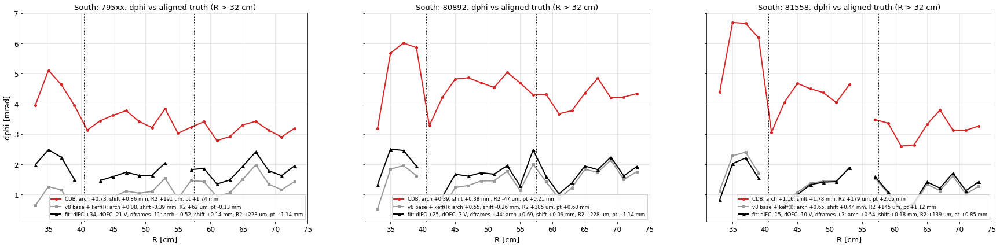

In [40]:
show(k8.fig_solutions(0))

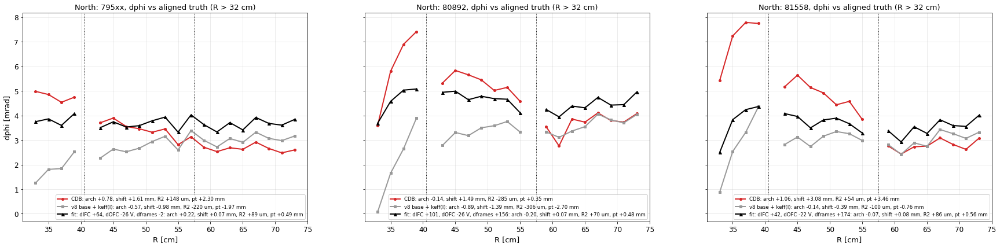

In [41]:
show(k8.fig_solutions(1))

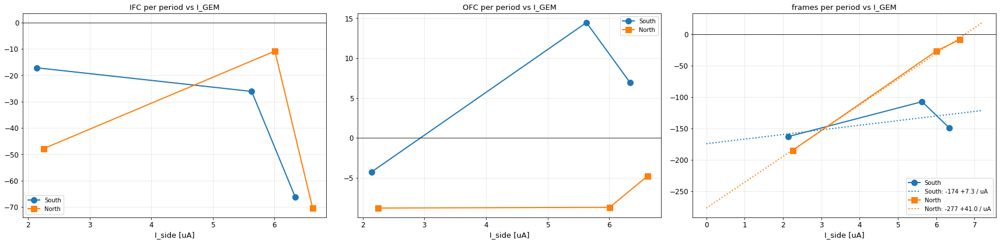

In [42]:
show(k8.fig_frames_vs_I())

**795xx static (K0s metric)**:

| | IFC | OFC | frames | dφ rms (CDB) | shift (CDB) | R² (CDB) | pointing (CDB) | steps | R1 arch (CDB) |
|---|---|---|---|---|---|---|---|---|---|
| South | −4 V | +4 V | −157 | 0.46 (0.56) | −0.01 (0.86) mm | +1 (+202*) µm | 0.03 (1.79*) mm | +0.02 / −0.02 | +0.58 (+0.73) |
| North | −43 V | −6 V | −182 | 0.25 (0.81) | +0.01 (1.61) mm | −6 (+148*) µm | −0.01 (2.29*) mm | −0.19 / −0.21 | +0.25 (+0.78) |

(* CDB in the R > 32 metric; in the K0s metric the CDB R² is −31 / +50 µm.)

- **Small voltages on both sides**, frames −157 / −182. The North IFC is no longer −112 … −138 V: that was compensating
  the too-small keff at 795xx (0.55–0.60 I instead of 0.68–0.70 I − 0.015 I²).
- **Per period**: the knobs scatter (IFC −17 / −26 / −66 S, −48 / −11 / −70 N; frames −163 / −108 / −149 S, −185 / −27 / −9 N):
  no trend with the current; 80892 and 81558 (same current) differ → **the static is time dependent**, not beam
  dependent. For the K0s runs (795xx) the 795xx static is the one to use.
- **8xxxx South steps −0.4 … −0.56 mm** remain (0 at 795xx; CDB −1.1 mm): they scale with the current → space-charge
  map at the module boundaries (density map gaps), not static.
- The **R1 frame weight** does not fix the South R1 arch and runs away at 8xxxx: dropped.

### 3.2 The final calibration run explicitly (v9) vs the CDB

In [43]:
v9.report()

================ South
 795xx, all bins (K0s metric):
   final: keff aI-0.015I^2, 795xx static      rms 0.45 shift +0.08 R2   +56 pt +0.36 st -0.01/+0.16 arch +0.67
   linear keff 0.60/0.55 I, same static       rms 0.62 shift +0.81 R2  +249 pt +1.90 st +0.06/+0.15 arch +1.16


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v9ana.py:10: RuntimeWarning: Mean of empty slice
  P = np.nanmean([k8.bp(tag, r, k, s, col) for r, k in bl], axis=0)


   final, P/T off                             rms 0.45 shift +0.08 R2   +58 pt +0.37 st -0.01/+0.16 arch +0.68
   CDB                                        rms 0.58 shift +0.50 R2   -31 pt +0.41 st -0.17/+0.28 arch +0.73
 795xx (R > 32):
   final, 795xx static                        rms 0.36 shift +0.43 R2  +275 pt +1.66 st -0.01/+0.16 arch +0.67
   final, own-period static                   rms 0.36 shift +0.43 R2  +275 pt +1.66 st -0.01/+0.16 arch +0.67
   linear keff                                rms 0.64 shift +1.06 R2  +437 pt +3.02 st +0.06/+0.15 arch +1.16
   P/T off                                    rms 0.37 shift +0.43 R2  +277 pt +1.68 st -0.01/+0.16 arch +0.68
   CDB                                        rms 0.56 shift +0.86 R2  +202 pt +1.79 st -0.17/+0.28 arch +0.73
 80892 (R > 32):
   final, 795xx static                        rms 0.53 shift +0.58 R2  +401 pt +2.41 st -0.70/-0.23 arch +1.17
   final, own-period static                   rms 0.44 shift +0.16 R2  +254 pt

   P/T off                                    rms 0.52 shift +0.55 R2  +384 pt +2.30 st -0.71/-0.23 arch +1.14
   CDB                                        rms 0.73 shift +0.38 R2   -12 pt +0.38 st -1.10/+0.10 arch +0.39
 81558 (R > 32):
   final, 795xx static                        rms 0.79 shift +1.31 R2  +393 pt +3.12 st -0.70/-0.10 arch +1.33
   final, own-period static                   rms 0.46 shift +0.31 R2  +189 pt +1.20 st -0.62/-0.14 arch +0.66
   linear keff                                rms 0.84 shift +1.44 R2  +428 pt +3.41 st -0.69/-0.09 arch +1.44


   P/T off                                    rms 0.78 shift +1.30 R2  +387 pt +3.08 st -0.70/-0.10 arch +1.32
   CDB                                        rms 1.19 shift +1.78 R2  +206 pt +2.75 st -1.23/-0.03 arch +1.16
 no beam / field off (795xx static, no SC, all bins):
   75073                                      rms 0.79 shift +0.95 R2   +48 pt +1.21 st -1.05/+0.37 arch +1.46


   83319                                      rms 0.57 shift +0.36 R2   +78 pt +0.71 st -0.71/+0.21 arch +1.16
   78242                                      rms 0.15 shift +0.21 R2  +113 pt +0.75 st -0.01/-0.10 arch +0.26
 P/T effect per run: f9_s795 - f9_nopt (R > 32)
   79508: E_eff +0.16% -> mean +0.002, rms 0.004 mrad, R2 +7 um, shift +0.005 mm
   79513: E_eff +0.01% -> mean +0.000, rms 0.000 mrad, R2 +0 um, shift +0.000 mm
   79516: E_eff -0.08% -> mean -0.001, rms 0.003 mrad, R2 -1 um, shift -0.004 mm
   79529: E_eff -0.47% -> mean -0.005, rms 0.011 mrad, R2 -12 um, shift -0.018 mm
   80892: E_eff +0.36% -> mean -0.002, rms 0.018 mrad, R2 +17 um, shift +0.032 mm
   81558: E_eff +0.10% -> mean -0.001, rms 0.006 mrad, R2 +5 um, shift +0.010 mm
================ North
 795xx, all bins (K0s metric):
   final: keff aI-0.015I^2, 795xx static      rms 0.26 shift +0.05 R2   +13 pt +0.13 st -0.21/-0.19 arch +0.31
   linear keff 0.60/0.55 I, same static       rms 0.72 shift +1.21 R2  +323 p

   final, P/T off                             rms 0.26 shift +0.05 R2   +14 pt +0.14 st -0.21/-0.20 arch +0.32
   CDB                                        rms 0.83 shift +1.45 R2   +50 pt +1.71 st -0.31/-0.13 arch +0.78
 795xx (R > 32):
   final, 795xx static                        rms 0.23 shift +0.21 R2  +108 pt +0.69 st -0.21/-0.19 arch +0.31
   final, own-period static                   rms 0.23 shift +0.21 R2  +108 pt +0.69 st -0.21/-0.19 arch +0.31
   linear keff                                rms 0.66 shift +1.21 R2  +370 pt +2.87 st -0.16/-0.19 arch +1.10
   P/T off                                    rms 0.23 shift +0.22 R2  +109 pt +0.70 st -0.21/-0.20 arch +0.32
   CDB                                        rms 0.81 shift +1.61 R2  +148 pt +2.29 st -0.31/-0.13 arch +0.78
 80892 (R > 32):
   final, 795xx static                        rms 0.50 shift -0.16 R2   +52 pt +0.16 st -0.78/-0.02 arch -0.01
   final, own-period static                   rms 0.36 shift +0.14 R2  +115 pt

   P/T off                                    rms 0.51 shift -0.19 R2   +40 pt +0.07 st -0.78/-0.03 arch -0.04
   CDB                                        rms 1.20 shift +1.49 R2  -265 pt +0.43 st -1.15/-0.70 arch -0.14
 81558 (R > 32):
   final, 795xx static                        rms 0.68 shift +0.84 R2  +257 pt +2.08 st -0.80/-0.05 arch +0.79
   final, own-period static                   rms 0.38 shift +0.13 R2  +129 pt +0.78 st +0.28/+0.17 arch -0.14
   linear keff                                rms 1.02 shift +1.79 R2  +515 pt +4.21 st -0.72/-0.04 arch +1.51


   P/T off                                    rms 0.68 shift +0.82 R2  +252 pt +2.05 st -0.80/-0.05 arch +0.78
   CDB                                        rms 1.72 shift +3.08 R2   +66 pt +3.49 st -1.13/-0.51 arch +1.06
 no beam / field off (795xx static, no SC, all bins):
   75073                                      rms 0.78 shift +1.15 R2   +61 pt +1.39 st -1.18/-0.22 arch +1.07


   83319                                      rms 1.19 shift +2.03 R2  +423 pt +3.80 st -0.64/+0.38 arch +1.50
   78242                                      rms 0.28 shift -0.21 R2   -88 pt -0.62 st +0.08/+0.84 arch -0.09
 P/T effect per run: f9_s795 - f9_nopt (R > 32)
   79508: E_eff +0.16% -> mean +0.003, rms 0.005 mrad, R2 +4 um, shift +0.009 mm
   79513: E_eff +0.01% -> mean +0.000, rms 0.000 mrad, R2 +0 um, shift +0.000 mm
   79516: E_eff -0.08% -> mean -0.003, rms 0.003 mrad, R2 -1 um, shift -0.005 mm
   79529: E_eff -0.47% -> mean -0.011, rms 0.014 mrad, R2 -5 um, shift -0.026 mm
   80892: E_eff +0.36% -> mean -0.003, rms 0.018 mrad, R2 +12 um, shift +0.029 mm
   81558: E_eff +0.10% -> mean +0.000, rms 0.007 mrad, R2 +5 um, shift +0.012 mm


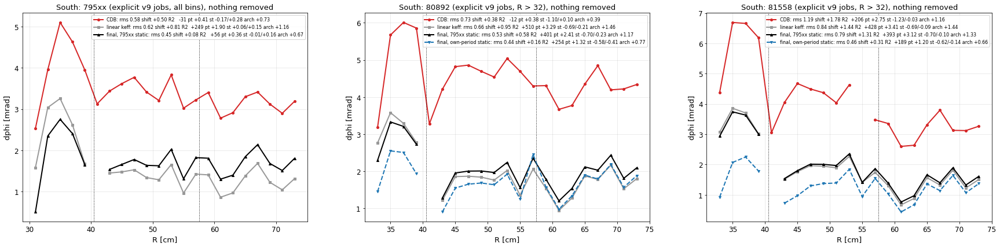

In [44]:
show(v9.fig_periods(0))

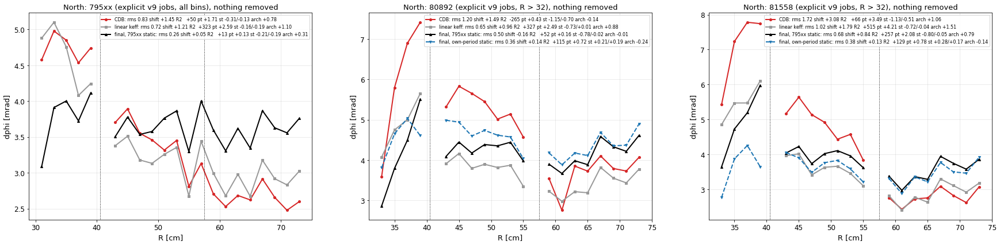

In [45]:
show(v9.fig_periods(1))

- 795xx: South dφ rms 0.45 (CDB 0.58), shift 0.08 (0.50) mm, R² +56 (−31) µm → K0s balance ≈ +66 µm; North 0.26 (0.83), 0.05
  (1.45) mm, +13 (+50) µm. (A South OFC change of ≈ −10 V would bring its R² to 0.)
- 8xxxx with the own-period static: 0.36–0.46 mrad (CDB 0.73–1.72), shift ≤ 0.3 mm (0.4–3.1); South steps −0.6 mm at high
  current (CDB −1.1 … −1.2): the space-charge density map at the module boundaries.
- Linear keff on the same static (comparison): R² +250 / +320 µm, shift 0.8 / 1.2 mm.

## 4. P/T and the drift velocity: can they explain what is left?
**What our jobs already do.** Every block runs with `cmv=pt@<f>`: the CM drift field E_eff = 376.85 V/cm × (P_ref/P)(T/T_ref)
from TPC_CONDITIONS at the block time (reference 79513), the effective-field prescription of the drift-velocity talks.
**What it does not do**: it scales only the drift field. A density change scales E/N of *every* field component – the
space-charge field and the field-cage and frame perturbations too – so the field *directions* stay the same and only the
mobility (ωτ = μB, the E×B part) changes. Scaling only E_z changes E_r/E_z by the same fraction: the transverse
drift-velocity components are not scaled together with the longitudinal one, as they should be. The right emulation is
to scale the whole field (or the gas table) by the P/T factor.

**Size.** E_eff per run vs 79513 (from the job logs) and the measured drift time t_CM − t0 (raw-time edges, t0 follow-up
talk); d ln v / d ln E ≈ 0.7 from the PHGarfield P/T scan:

In [46]:
E = {'79508': 377.44, '79513': 376.88, '79516': 376.53, '79529': 375.08, '80892': 378.21, '81558': 377.21}
tS = {'79513': 251.05 - 8.40, '79516': 251.51 - 8.39, '79529': 253.18 - 8.36, '80892': 251.27 - 8.58, '81558': 250.62 - 8.67}
tN = {'79513': 251.63 - 8.46, '79516': 252.08 - 8.49, '79529': 253.70 - 8.40, '80892': 251.49 - 8.65, '81558': 251.11 - 8.78}
d3.SPLIT_SOUTH = False
fr = d3.fit_keff(0, 'v7', 'free'); runs = [r for r, k, a, b in d3.blocks()]
kI = {r: np.mean([k / i for rr, k, i in zip(runs, fr['k'], fr['I']) if rr == r]) for r in d3.RUNS}
k0 = np.mean([kI['79513'], kI['79516']])
print(f"{'run':8s} {'E_eff vs 79513':>14s} {'P/T: drift time':>16s} {'measured S / N':>18s} {'not P/T S / N':>16s} {'keff/I (S) vs 795xx':>20s}")
for r in ('79508', '79513', '79516', '79529', '80892', '81558'):
    e = (E[r] / E['79513'] - 1) * 100; pt = -0.7 * e
    if r in tS:
        ms = (tS[r] / tS['79513'] - 1) * 100; mn = (tN[r] / tN['79513'] - 1) * 100
        print(f"{r:8s} {e:+13.2f}% {pt:+15.2f}% {ms:+8.2f}% / {mn:+6.2f}% {ms - pt:+7.2f}% / {mn - pt:+5.2f}% {(kI[r] / k0 - 1) * 100:+19.1f}%")
    else:
        print(f"{r:8s} {e:+13.2f}% {pt:+15.2f}% {'-':>18s} {'-':>16s} {(kI[r] / k0 - 1) * 100:+19.1f}%")
print('(81558: timing from 81566, the nearest run in the talk)')
d3.SPLIT_SOUTH = True

run      E_eff vs 79513  P/T: drift time     measured S / N    not P/T S / N  keff/I (S) vs 795xx
79508            +0.15%           -0.10%                  -                -                +2.5%
79513            +0.00%           -0.00%    +0.00% /  +0.00%   +0.00% / +0.00%                -0.1%
79516            -0.09%           +0.07%    +0.19% /  +0.17%   +0.13% / +0.11%                +0.1%
79529            -0.48%           +0.33%    +0.89% /  +0.88%   +0.56% / +0.54%                +4.1%
80892            +0.35%           -0.25%    +0.02% /  -0.14%   +0.26% / +0.11%                -0.4%
81558            +0.09%           -0.06%    -0.29% /  -0.35%   -0.23% / -0.28%                +2.8%
(81558: timing from 81566, the nearest run in the talk)


- **P/T is not small for the correction as a whole.** The distortions themselves are ≈ 0.5–1 cm in RΔφ (static E×B ≈ 5–7 mm,
  space charge up to ≈ 10 mm at 6 µA). A gas-density change of 1–2 % changes the mobility (the Lorentz angle) and so the E×B
  part by ≈ 1–2 % → **≈ 50–150 µm**. Our jobs apply P/T only to E_z, which reproduces only a fraction of that: the v9 on − off
  difference (≤ 0.02 mrad, ≤ 0.03 mm) is the effect of that partial implementation, not of P/T. The v10 jobs scale all fields
  (and ω-tau, and B) by ±1–2 % to measure the full effect.
- **What P/T misses** (the fill-to-fill drift-velocity offsets of the talks) is larger: 79529 drifts ≈ 0.55 % slower than
  P/T predicts on both sides (the 79528 / 79529 CM edge at 253.2 instead of ≈ 251). A 0.5–1 % E/N error moves the
  correction by ≈ 0.5–1 %: ≤ 0.04 mrad at 795xx, ≤ 0.12 mrad at 6 µA.
- **Our run anomalies do not follow it**: 79529 wants ≈ +4 % keff (several times what its dv offset could give), 79508 and
  81558 ≈ +2.5 % with no or the opposite dv offset, 80892 −0.4 %. The keff spread between runs (± 2–4 %) is not the
  drift velocity; more likely the GEM-current ↔ ion-density relation per run (gain, IBF, current read-back).
- **Can PHGarfield do it right**: yes – scale keff and the static perturbations with the same P/T factor as the drift field
  (or evaluate the gas table at E/N directly); v10 measures how large the full effect is.

**v9, P/T on − off** (only E_z scaled): ≤ 0.018 mrad rms, shift ≤ 0.03 mm, R² ≤ 17 µm – the partial implementation; the full effect (all fields, ω-tau, B ±1–2 %) is measured by v10.

## 5. Final calibration vs the CDB (nothing removed)
### 5a. 795xx: dφ vs R, φ-averaged and in four φ bins

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v5ana.py:336: RuntimeWarning: Mean of empty slice
  _DP[k] = np.nanmean(P, axis=0) if P else np.full(len(ta.PRC), np.nan)


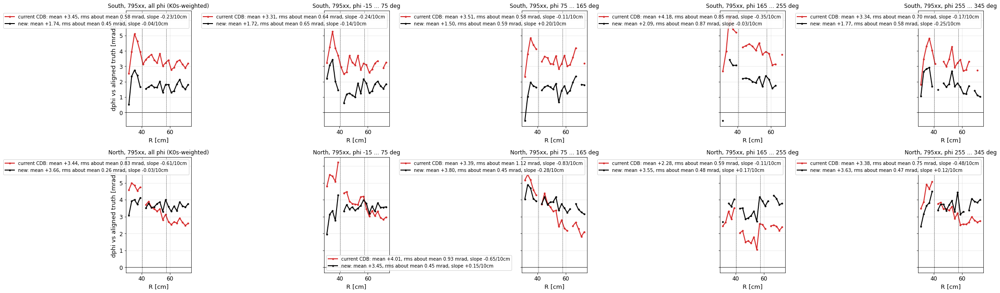

In [47]:
v.FINAL_TAG = 'f9_s795'; v.FINAL_LAB = 'final calibration'
show(v.fig_cmp_dphi())

### 5b. 795xx: dR vs R (all two-row clusters)

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/v5ana.py:367: RuntimeWarning: Mean of empty slice
  return np.nanmean(D, axis=0) if D else np.full(len(E) - 1, np.nan)


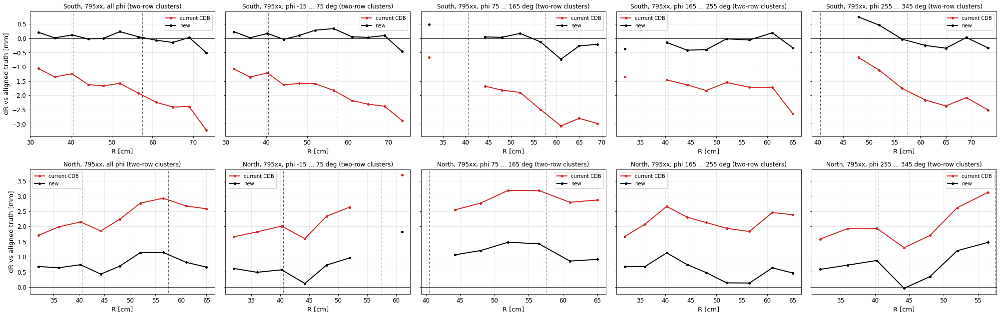

In [48]:
show(v.fig_cmp_dR())

### 5c. 795xx: R² and pointing per 30° sector

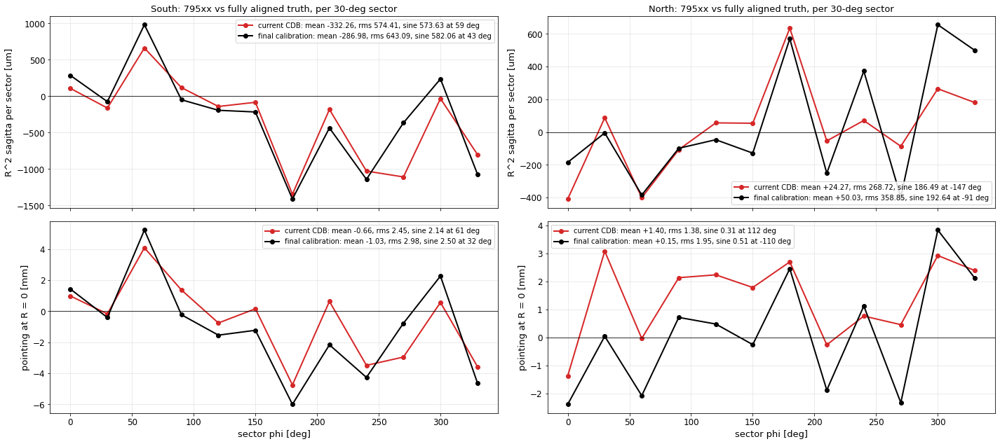

In [49]:
show(v.fig_final_sectors())

### 5d. 80892 + 81558 (own-period static): dφ in φ bins and dR

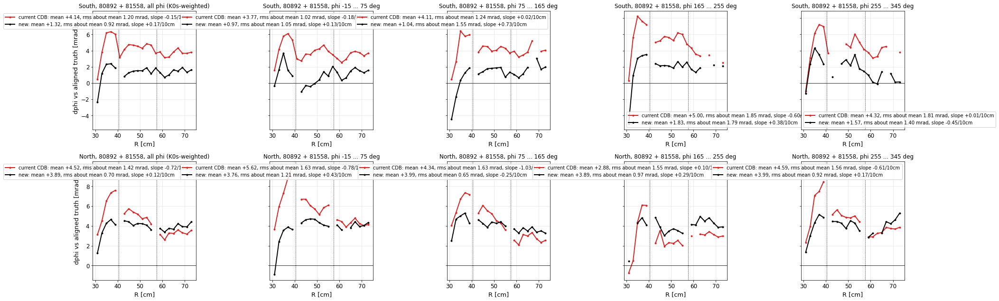

In [50]:
v.FINAL_TAG = 'f9_sper'
show(v.fig_cmp_dphi(runs=('80892', '81558'), title='80892 + 81558'))

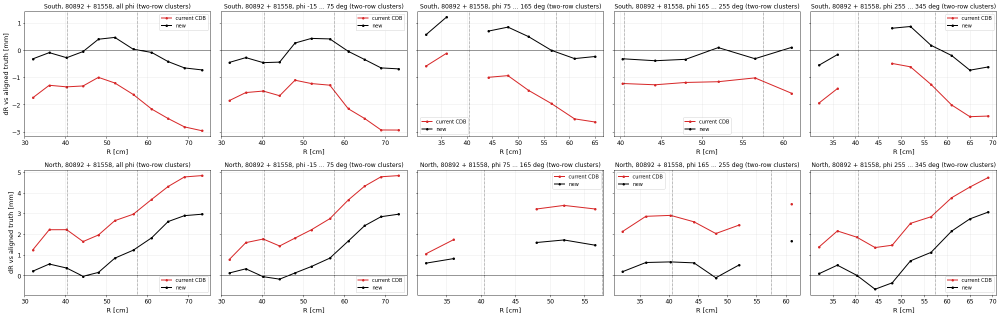

In [51]:
show(v.fig_cmp_dR(runs=('80892', '81558'), title='80892 + 81558'))
v.FINAL_TAG = None

### 5e. Per-sector sagittas: what is real?
Per 30° sector R² and pointing. Three effects have to be separated: (1) the estimator, (2) static per sector, (3) space charge
per sector (GEM gain × IBF per module).

In [52]:
cf.sector_table()

South                                                                     rms over sectors    sine amplitude at phase


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/calfinal.py:196: RuntimeWarning: Mean of empty slice
  return np.nanmean(D, axis=0)


      no beam 75073, final static                                                396 um             117 um    at   +43 deg
      no beam 83319, final static                                                345 um             143 um    at  +151 deg
      795xx static only (raw data space charge + static)                         778 um             202 um    at  -109 deg
      measured space-charge change per uA (8xxxx - 795xx, static only)           204 um/uA           33 um/uA at  -147 deg
      the correction itself, 795xx (final - static only; matched sets differ, see below)         982 um             766 um    at   +50 deg
      the correction itself, 8xxxx (final - static only; matched sets differ, see below)        1550 um            1245 um    at   +57 deg
      795xx final                                                                643 um             582 um    at   +43 deg
      795xx CDB                                                                  574 um             574 um 

      no beam 75073, final static                                                412 um             337 um    at  -116 deg
      no beam 83319, final static                                                413 um             133 um    at  -124 deg
      795xx static only (raw data space charge + static)                         495 um             341 um    at  -161 deg
      measured space-charge change per uA (8xxxx - 795xx, static only)           249 um/uA          193 um/uA at   +77 deg
      the correction itself, 795xx (final - static only; matched sets differ, see below)         401 um             328 um    at   -14 deg
      the correction itself, 8xxxx (final - static only; matched sets differ, see below)        1086 um            1260 um    at   -78 deg
      795xx final                                                                359 um             193 um    at   -91 deg
      795xx CDB                                                                  269 um             186 um 

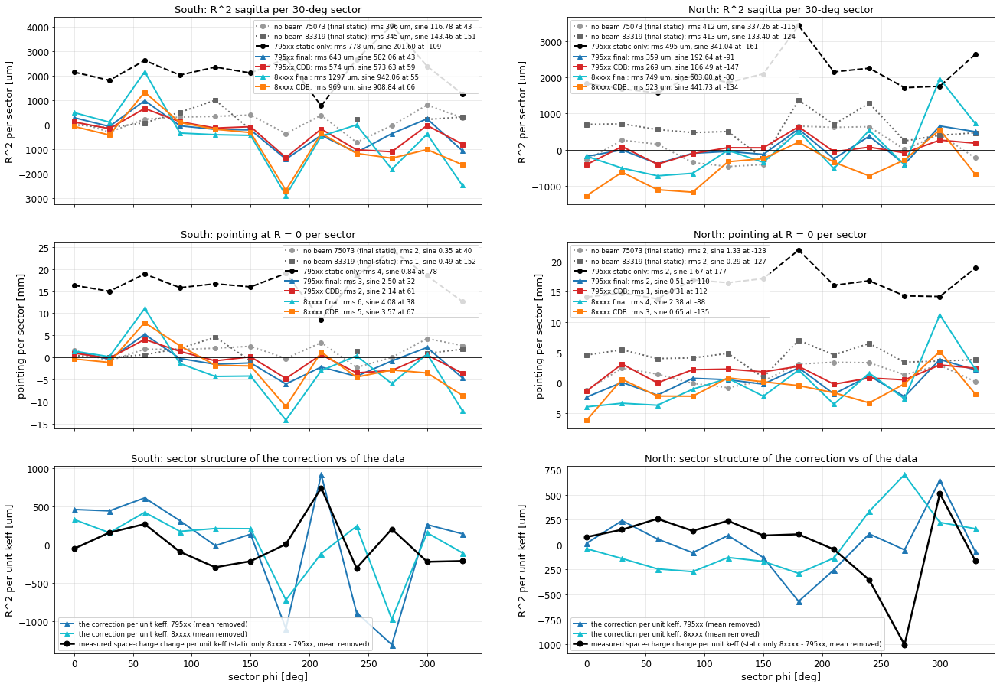

In [53]:
show(cf.fig_sector_origin())

**(1) The estimator: R coverage.** The correction's R profile is the same in every sector, but some sectors (South 6–9) miss
outer R bins (no CM clusters there) – a quadratic fit over a truncated range turns the same correction into a different R²
(the ±1.5–1.9 mm "features" of South sectors 6 and 9 above). Fixed cluster set (each raw cluster matched to the same stripe in
every configuration), 795xx South:

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/fixedset.py:72: RuntimeWarning: Mean of empty slice
  return {t: np.nanmean(D[t], axis=0) for t in tags}


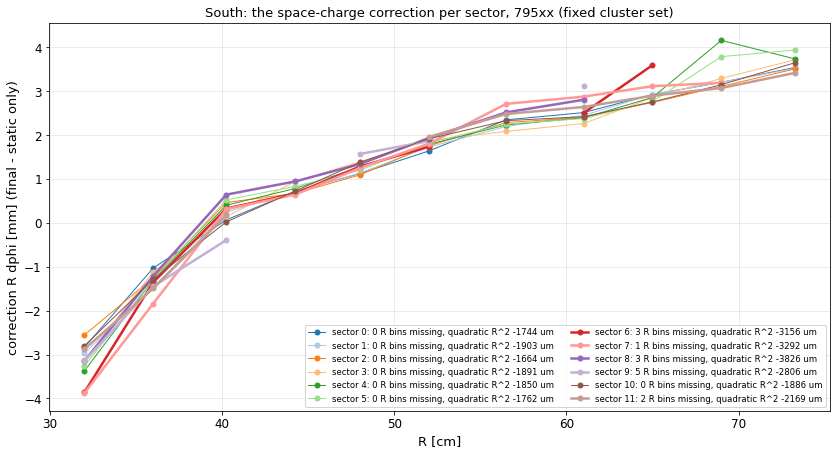

In [54]:
show(cf.fig_coverage(0))

**Coverage-independent per-sector R²**: the φ-averaged profile plus a quadratic fit to (sector − φ average) on the bins the
sector has, on the fixed cluster set. The map's own φ structure (per-layer gain of 79513) is small:

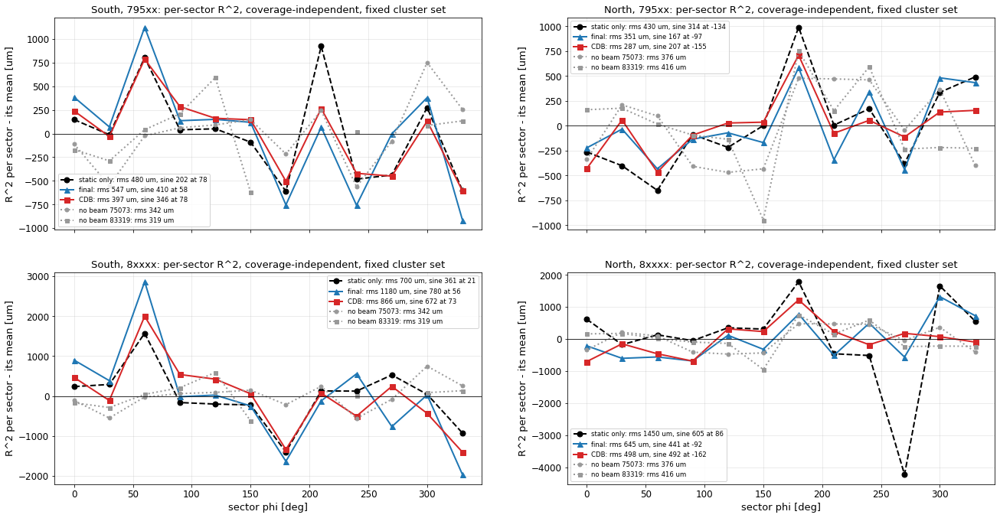

In [55]:
show(cf.fig_sector_robust())

In [56]:
cf.map_phi_structure()

South: gain file layer_gain_79513_Mariia_side01.root (hGainMap_side0_South), rho_corrected = rho_base / gain, phi harmonics <= 24
   E_r at r = 35 cm per sector / mean: 1.09 1.07 1.03 1.01 0.99 0.98 0.97 0.95 0.93 0.96 0.98 1.02  (spread 0.046)
   E_r at r = 50 cm per sector / mean: 1.02 1.04 1.07 1.07 1.04 0.93 0.89 0.93 0.99 1.02 1.00 1.01  (spread 0.055)
   E_r at r = 65 cm per sector / mean: 1.06 1.08 1.04 0.97 0.97 0.98 0.98 0.96 0.95 0.98 1.00 1.03  (spread 0.042)


North: gain file layer_gain_79513_Mariia_side01.root (hGainMap_side1_North), rho_corrected = rho_base / gain, phi harmonics <= 24
   E_r at r = 35 cm per sector / mean: 1.00 0.99 0.97 0.97 1.03 1.07 1.03 1.01 0.98 0.94 1.00 1.02  (spread 0.034)
   E_r at r = 50 cm per sector / mean: 1.04 0.97 1.03 1.04 1.00 0.98 0.96 0.98 0.97 0.92 1.00 1.11  (spread 0.049)
   E_r at r = 65 cm per sector / mean: 0.99 1.01 1.03 1.02 0.97 0.97 1.01 1.01 0.97 0.98 1.02 1.01  (spread 0.021)


**(2) + (3) What is real** (South): sector 2 (60°) +700 µm and sector 6 (180°) −700 µm vs the φ average in the static-only data
at 795xx, +1550 / −1430 µm at 8xxxx, ≈ 0 without beam: they **grow with the current → space charge per sector**. The
φ-symmetric correction (ours and the CDB) under-corrects sector 2 and over-corrects sector 6 – the same φ (≈ 60° and ≈ 190°) as
the TPC-only tracks' charge-odd rDCA and pT-slope ratio (atan2(px, py) ≈ 0.3–0.9 rad and −1.8 rad). The space-charge scale
per sector from the 795xx → 8xxxx change, and what applying it does:

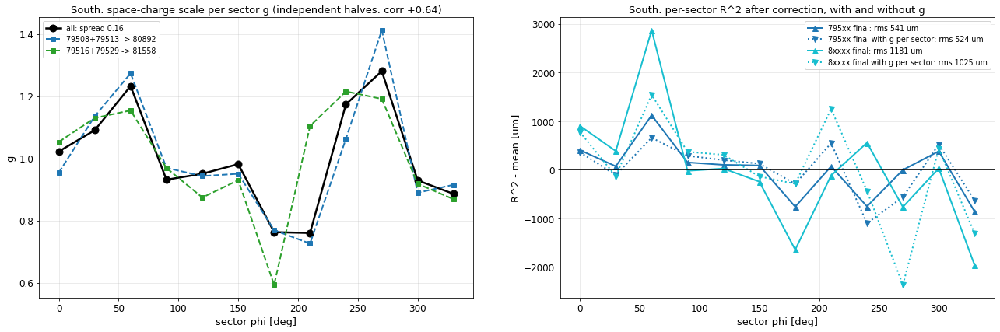

In [57]:
show(cf.fig_sector_gain())

- g per sector (South): 0.76 (sectors 6, 7) … 1.23–1.28 (sectors 2, 9), spread 0.16; reproduced by two independent halves
  (corr +0.64, scatter 0.11) → real (GEM gain × IBF per sector).
- Applying it flattens the per-sector R² only partly (795xx 541 → 524 µm, 8xxxx 1181 → 1025 µm): the rest is static per sector
  (no beam alone ≈ 330 µm rms). North: its static moves between 795xx and 8xxxx, so g needs current levers inside one period.
- **To apply it for real**: a density map with per-sector (per-module) weights g – the next map production.

### 5f. The static between no-beam runs (75073 → 83319)

In [58]:
cf.nobeam_change()

South 83319 - 75073: rms 0.47 mrad, mean -0.33 | rotation +0.04 mrad + IFC -32 -> left 0.37 mrad
South 83319 - 75073: rms 0.47 mrad, mean -0.33 | rotation -0.42 mrad + IFC -34, OFC -36 -> left 0.36 mrad
South 83319 - 75073: rms 0.47 mrad, mean -0.33 | rotation -0.64 mrad + IFC -30, OFC -54, frames +147 -> left 0.31 mrad
      sideways shift 75073 +0.95 mm -> 83319 +0.36 mm; R2 +48 -> +78 um


North 83319 - 75073: rms 0.63 mrad, mean +2.73 | rotation +2.09 mrad + IFC +54 -> left 0.32 mrad
North 83319 - 75073: rms 0.63 mrad, mean +2.73 | rotation +1.36 mrad + IFC +48, OFC -59 -> left 0.30 mrad
North 83319 - 75073: rms 0.63 mrad, mean +2.73 | rotation +1.73 mrad + IFC +52, OFC -32, frames +202 -> left 0.19 mrad
      sideways shift 75073 +1.15 mm -> 83319 +2.03 mm; R2 +61 -> +423 um


- North: mostly a **rotation of ≈ 1.5–2 mrad** (sideways shift 1.15 → 2.03 mm) plus an IFC-like change of ≈ +50 V; South: IFC
  ≈ −30 V, OFC ≈ −35 V. Frames add little. P/T cannot do it (≤ 0.05 mrad for 1 %).
- So between periods the static changes by field-cage voltages (tens of V) and a rotation-like term. With nothing rotated
  physically, that term has to be a field effect – the E×B scale (P/T via the mobility, the magnet current, the CM voltage).

## 6. Summary
- **Space charge**: keff = a I − 0.015 I² (a 0.70 S / 0.68 N; per-side median GEM current); South α 1.7 kink 25, North α 1.6
  kink 25; ≈ 0.08 mrad per block left; per-module scales 0.6–1.3 (≈ 15 % more, not yet applied).
- **Static** (795xx): South IFC −4 / OFC +4 V / frames −157, North IFC −43 / OFC −6 V / frames −182 (m = 120 frames); own
  static per period at 8xxxx.
- **vs CDB**: 795xx dφ rms 0.45 / 0.26 mrad (0.58 / 0.83), shift 0.08 / 0.05 mm (0.50 / 1.45), R² +56 / +13 µm (−31 / +50);
  8xxxx 0.36–0.46 mrad (0.73–1.72).
- **Left**: South R1 arch ≈ +0.6 mrad (static, also without beam); South module steps −0.6 mm at high current (density-map
  gaps); keff level per period vs static degenerate (keff(0) = 0 assumed); P/T negligible.
- **Per-sector sagittas** (5e): partly an estimator artifact (R coverage, South sectors 6–9), partly real space charge per sector (South g 0.76–1.28, sectors 2 and 6 = the tracks' φ features); the rest static per sector. Per-module weights in the density map are the next step.
- **No-beam static change** (5f): a rotation-like part (North 1.5–2 mrad) + field-cage voltages; P/T (≈ 50–150 µm per 1–2 %) is part of it – v10 measures it.
- **Next**: K0s run on 795xx with this calibration (expected balance ≈ +66 / +18 µm; South OFC −10 V → 0); density map with
  filled module gaps and per-module weights.